# Análise Integrada Global: Aglomerações Urbanas (CCA), Bacias Hidrográficas (IPBA) e Microplásticos Costeiros

Pipeline padrão-ouro v2 (`notebooks/executar_pipeline_global.py`), seguindo Oliveira et al. (2019), *Sci. Rep.* 9:9845:

1. **Blocos hidrológicos contíguos (GEBCO 2026)**: a percolação de sítios ($h > 0$ m) é agrupada em **2 blocos** (Américas; Afro-Eurásia + Oceania), para que nenhuma bacia seja cortada por uma caixa arbitrária. O Nilo, por exemplo, fica inteiro em um único bloco.
2. **IPBA + endorreísmo**: as bacias são delineadas pelo IPBA do orientador (`notebooks/IPBA`). As depressões sem saída ao mar ancoradas em lagos terminais documentados (Cáspio, Aral, Chade, Eyre, Great Basin...) recebem `is_endorheic=True` e são **excluídas dos emissores marinhos**.
3. **Zipf dinâmico + CCA**: em cada uma das 6 regiões demográficas disjuntas, varre-se $D \in [100, 2000]$ hab/km² (passo 100) $\times$ $L \in [1000, 5000]$ m (passo 500) e escolhe-se $\min |\alpha - 1|$ sujeito a $R^2 \geq 0{,}98$ no rank-size OLS das 100 maiores manchas. **Não há $D^*/L$ fixos.**
4. **Acoplamento bacia–cidade**: as manchas urbanas que cruzam divisores são particionadas somando a contagem de habitantes por pixel em cada bacia.
5. **NOAA (GeoJSON NCEI Hub)**: só entram coletas costeiras (sem `Ocean water`). Cada foz é pareada ao site mais próximo, $R \in \{15, 25, 38, 50\}$ km, e a alometria $(M \times A) \propto P^\beta$ usa bootstrap de 10.000 reamostragens. Os resultados são comparados entre os cenários A (baseline v1), B (hidrologia v2 + NOAA legado) e C (hidrologia v2 + NOAA nova).


In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for p in (REPO_ROOT, REPO_ROOT / "notebooks" / "CCA", REPO_ROOT / "notebooks" / "IPBA"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from cca.city_clustering import cca_grid
from drainage_basins import run_ipba_grid
from calculos import (
    R_EARTH_KM,
    ajuste_escala_log_log,
    leave_one_out_alometria,
    calibrar_zipf_dinamico,
    identificar_bacias_endorreicas,
)
from notebooks.gebco_cluster_dvider.geotiff.geotiff import ReadGeoTiff

RESULTS_DIR = REPO_ROOT / "notebooks" / "results"
GRAFICOS_DIR = REPO_ROOT / "geracao_graficos"
CATALOGO_PATH = REPO_ROOT / "notebooks" / "gebco_cluster_dvider" / "datasets" / "processed" / "catalogo_territorios_ilhas.json"
pd.set_option("display.width", 200)

print("CCA do orientador :", cca_grid.__module__)
print("IPBA do orientador:", run_ipba_grid.__module__)
print("Raio terrestre     :", R_EARTH_KM, "km")


CCA do orientador : cca.city_clustering
IPBA do orientador: drainage_basins.drainage_basins
Raio terrestre     : 6378.137 km


---
## 1. Percolação Global e Blocos Hidrológicos Contíguos (GEBCO 2026)

A área esférica de cada pixel é a soma de **dois triângulos esféricos** (L'Huilier, $R_\oplus = 6378{,}137$ km). As massas de terra ($h > 0$ m, 4-vizinhança) são atribuídas a um bloco pelo centróide. O Mar Negro, o Mar de Azov e o Mar de Mármara recebem sementes marinhas, porque os estreitos são sub-pixel na grade de 2'.


Clusters terrestres globais (h > 0 m): 4,735
Área emersa global: 149,489,637.2 km²



,id,nome_pt,n_massas_terra,area_esferica_km2,bbox_lon_lat,shape_hw
0,bloco_americas,"Bloco Ocidental: Américas (Norte, Central, Car...",1526,41890921.54,"[-175.3, -56.0, -11.5, 83.7]","[4191, 4914]"
1,bloco_afroeurasia_oceania,Bloco Oriental: Afro-Eurásia e Oceania,2669,93187201.06,"[-25.1333, -49.7667, 190.4, 77.7667]","[3826, 6466]"


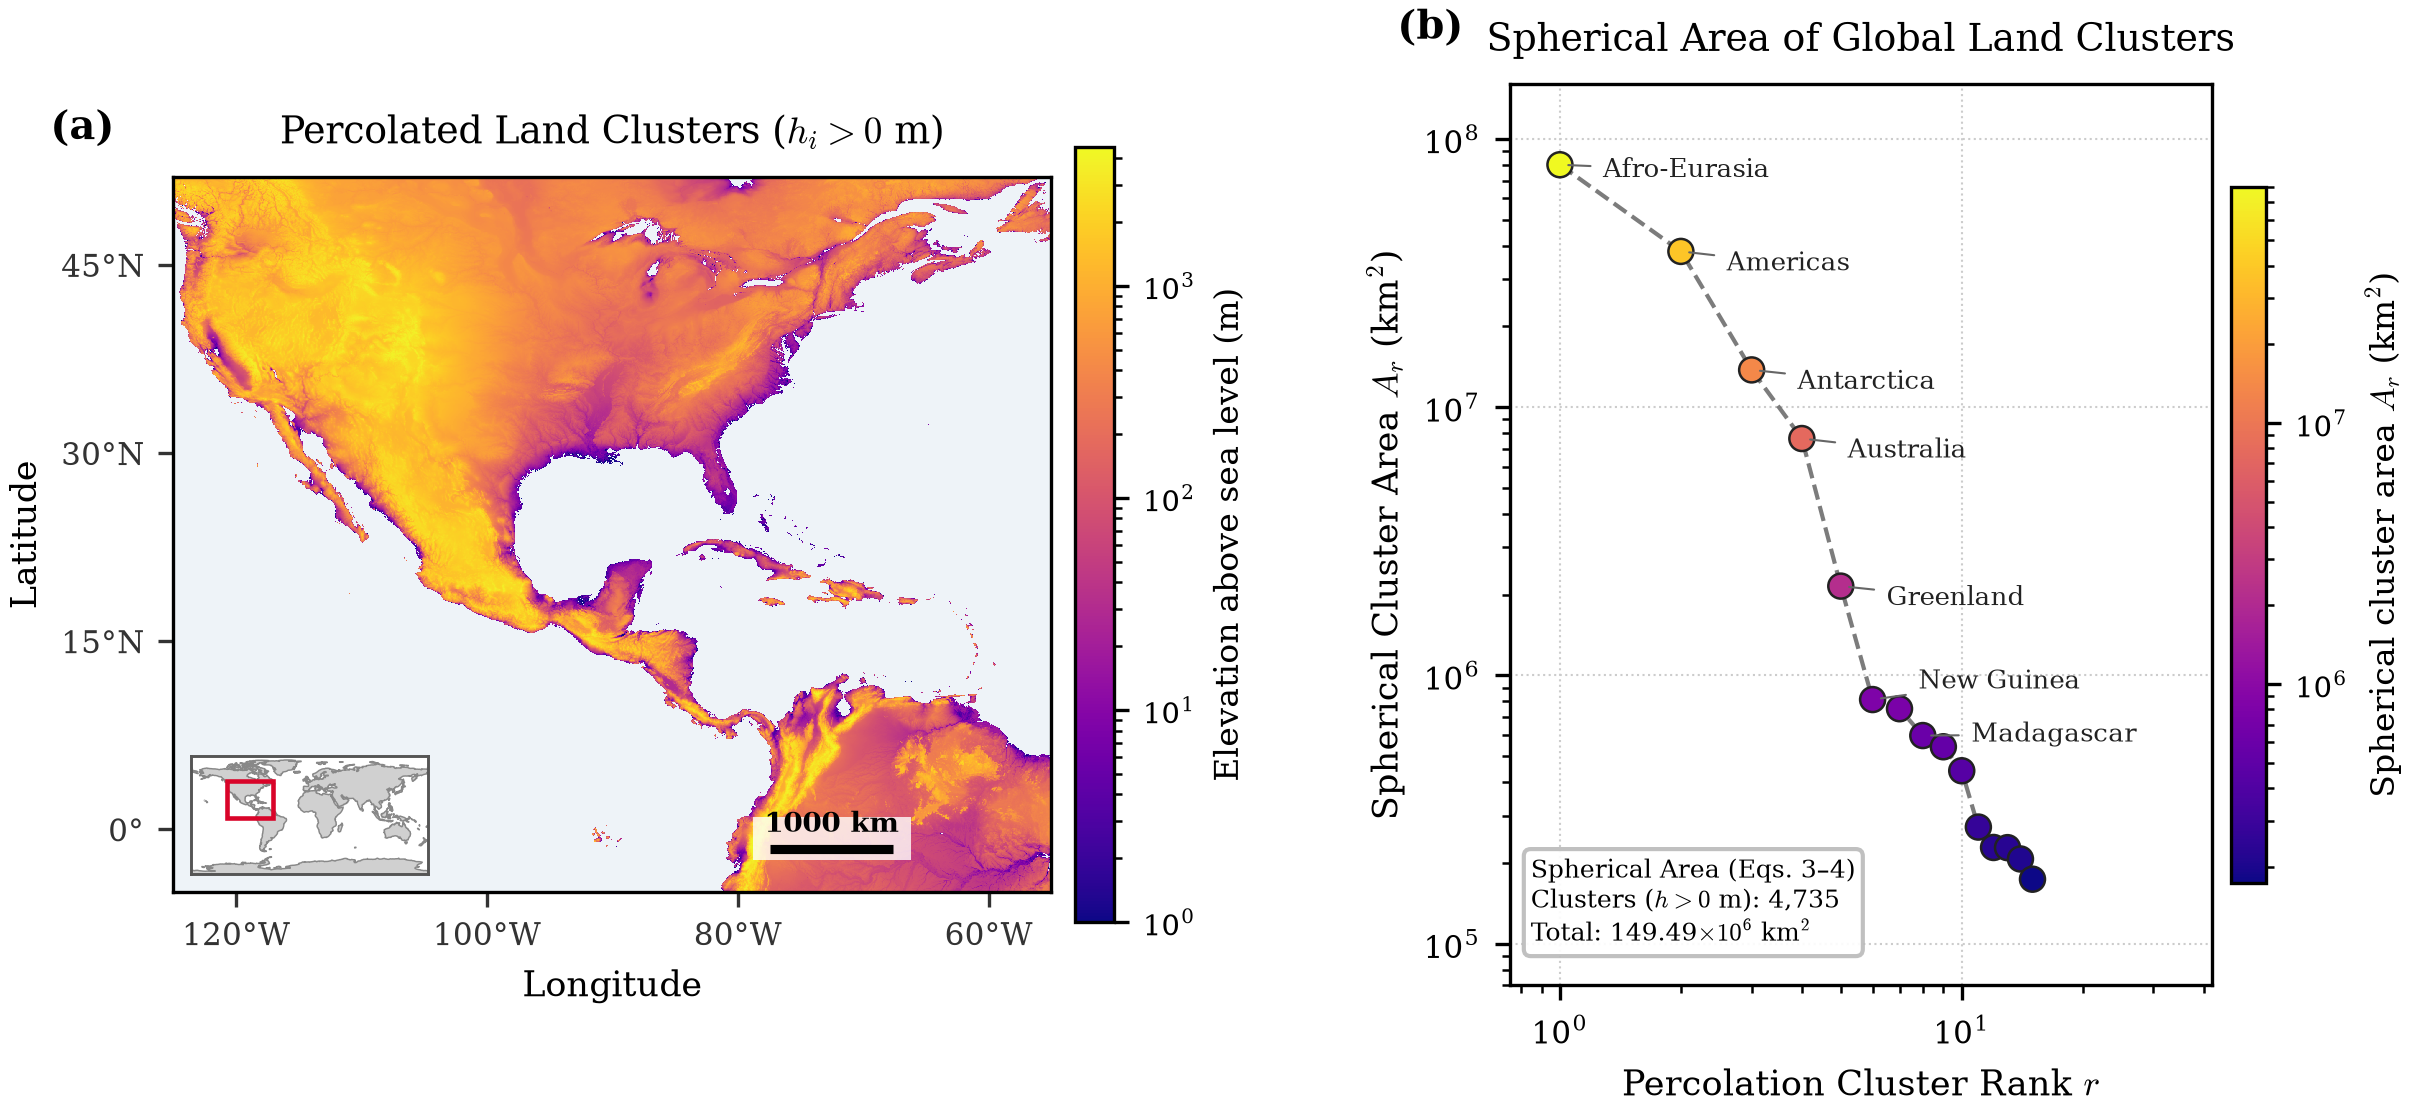

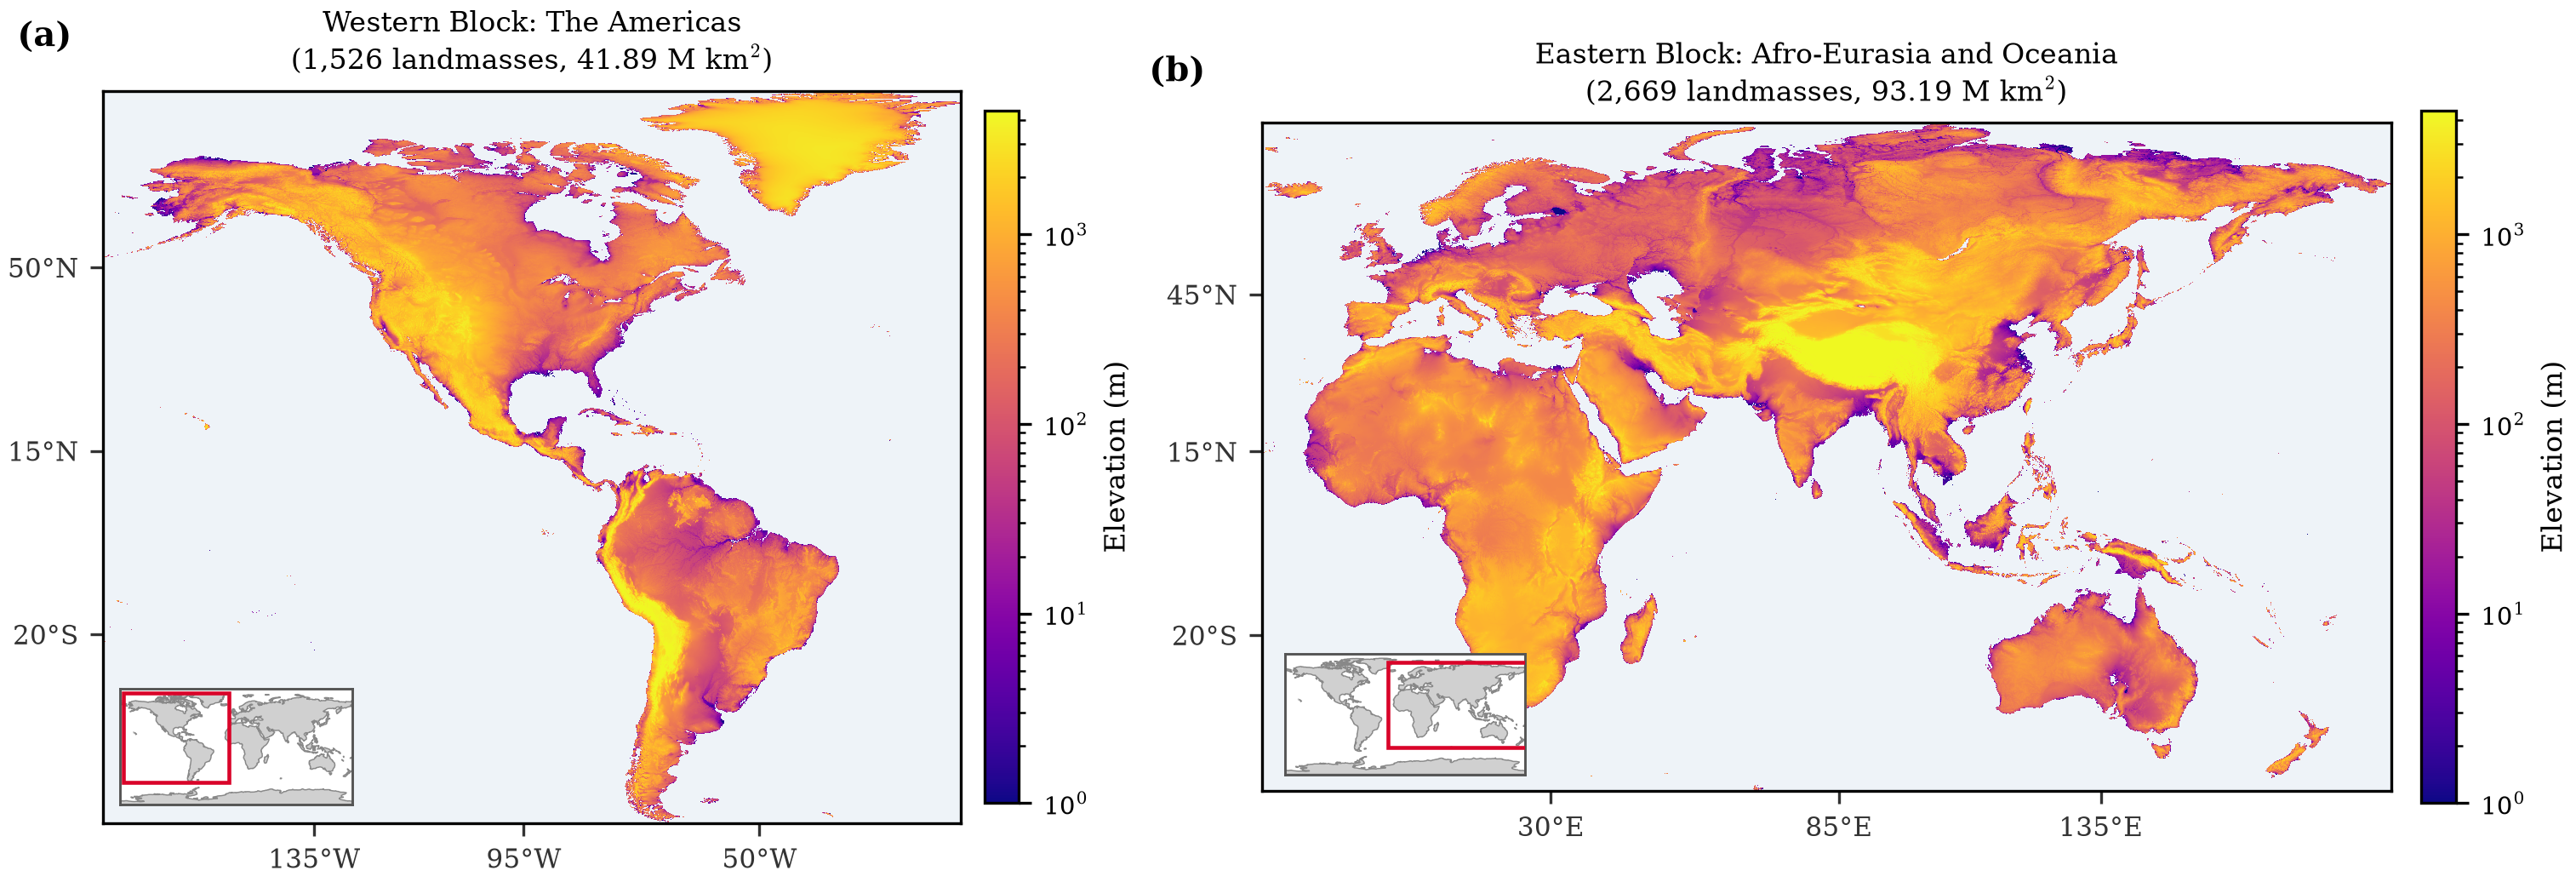

In [2]:
with open(CATALOGO_PATH, "r", encoding="utf-8") as f:
    catalogo = json.load(f)
print(f"Clusters terrestres globais (h > 0 m): {catalogo['total_clusters_globais']:,}")
print(f"Área emersa global: {catalogo['area_emersa_global_km2']:,.1f} km²\n")
display(pd.DataFrame(catalogo["blocos_hidrologicos"])[
    ["id", "nome_pt", "n_massas_terra", "area_esferica_km2", "bbox_lon_lat", "shape_hw"]
])
display(Image(filename=str(GRAFICOS_DIR / "gebco" / "gebco_global_islands_clusters.png"), width=880))
display(Image(filename=str(GRAFICOS_DIR / "gebco" / "gebco_hydrological_blocks.png"), width=880))


---
## 2. IPBA em 2 Blocos, Bacias Endorreicas e Validação contra a Literatura

O IPBA roda uma vez por bloco. Depois, o *priority-flood* (Barnes, 2014) identifica as depressões fechadas. Só são aceitas como endorreicas as depressões que contêm um lago terminal documentado (`SISTEMAS_ENDORREICOS`), e o transbordamento só é permitido sobre a superfície preenchida de referência. Isso evita que gargantas estreitas, não resolvidas a 2', sejam lidas como barreiras. As bacias exorreicas recebem rótulos positivos, as endorreicas negativos, e só as **exorreicas que acumulam $P = 0{,}90$ da área ($A \geq 4.500$ km²)** entram no pareamento.


Bacias de referência dentro de ±20%: 21/30


,bacia,area_literatura_km2,area_ipba_endo_km2,desvio_%,status
0,Amazon,6100000.0,5779262.2,-5.3,ok
1,Congo,3700000.0,3801842.7,2.8,ok
2,Nile,3250000.0,3794300.0,16.7,ok
3,Mississippi,3200000.0,2963120.9,-7.4,ok
4,Parana / La Plata,3100000.0,3333117.3,7.5,ok
5,Ob,2990000.0,4524536.5,51.3,fora da tolerancia
6,Yenisei,2580000.0,700716.7,-72.8,fora da tolerancia
7,Lena,2490000.0,2397781.7,-3.7,ok
8,Niger,2270000.0,2773173.7,22.2,fora da tolerancia
9,Amur,1860000.0,2724219.3,46.5,fora da tolerancia


,ponto,lon,lat,rotulo_bacia
0,Cairo (ápice do delta),31.25,30.05,52248
1,Aswan,32.90,24.09,52248
2,Atbara,33.98,17.70,52248
3,Cartum (confluência),32.53,15.60,52248
4,Lago Tana (Nilo Azul),37.30,12.00,52248
5,Juba (Nilo Branco),31.60,4.85,52248
6,Lago Alberto,30.90,1.70,52248
7,Lago Vitória (Jinja),33.20,0.42,52248


Nilo: bacia única e exorreica (rótulo 52248 )

Bacias endorreicas: 37 | área total 19.97 Mkm² | população 408.3 M hab (excluída dos emissores marinhos)


,global_basin_uid,nome_sistema_endorreico,area_km2,pop_total,profundidade_m
0,bloco_afroeurasia_oceania__E1,Caspian Sea,3528126.0,118440062.0,1076.0
1,bloco_afroeurasia_oceania__E26,Lake Chad + Bodele Depression,2467072.0,67239753.0,167.0
2,bloco_afroeurasia_oceania__E6,Aral Sea + Sarysu terminal lakes + Chu termina...,1605402.0,62068281.0,40.0
3,bloco_afroeurasia_oceania__E31,Lake Eyre,1304865.0,51819.0,100.0
4,bloco_afroeurasia_oceania__E8,Tarim / Lop Nur,1231906.0,14081963.0,1395.0
5,bloco_afroeurasia_oceania__E5,Lake Balkhash + Lake Alakol / Ebinur,1141689.0,17059391.0,300.0
6,bloco_afroeurasia_oceania__E23,Sebkha Mekerrhane (Tidikelt),1036887.0,1497017.0,179.0
7,bloco_afroeurasia_oceania__E17,Chott Melrhir / Chott el Djerid,900584.0,9311160.0,78.0
8,bloco_afroeurasia_oceania__E21,Kufra Basin,892755.0,1267794.0,45.0
9,bloco_afroeurasia_oceania__E7,Gobi / Juyan Lake,639004.0,3319855.0,285.0


Nenhuma bacia endorreica na tabela de alometria.


,bloco_id,area_min_km2,prof_min_m,n_candidatas,n_endorreicas,area_endorreica_km2,sistemas_sem_correspondencia
0,bloco_americas,500.0,20.0,955,6,887120.0,Laguna Mar Chiquita
1,bloco_americas,5000.0,20.0,70,6,887120.0,Laguna Mar Chiquita
2,bloco_americas,1000.0,10.0,526,7,1261679.3,NaN
3,bloco_americas,1000.0,50.0,321,6,887120.0,Laguna Mar Chiquita
4,bloco_americas,1000.0,20.0,465,6,887120.0,Laguna Mar Chiquita
5,bloco_afroeurasia_oceania,500.0,20.0,2167,31,18196327.9,Lake Torrens
6,bloco_afroeurasia_oceania,5000.0,20.0,239,31,19771853.9,Lake Torrens
7,bloco_afroeurasia_oceania,1000.0,10.0,1192,32,19316450.4,NaN
8,bloco_afroeurasia_oceania,1000.0,50.0,785,28,19140235.5,Lake Tengiz;Lake Torrens
9,bloco_afroeurasia_oceania,1000.0,20.0,1092,31,19082590.8,Lake Torrens


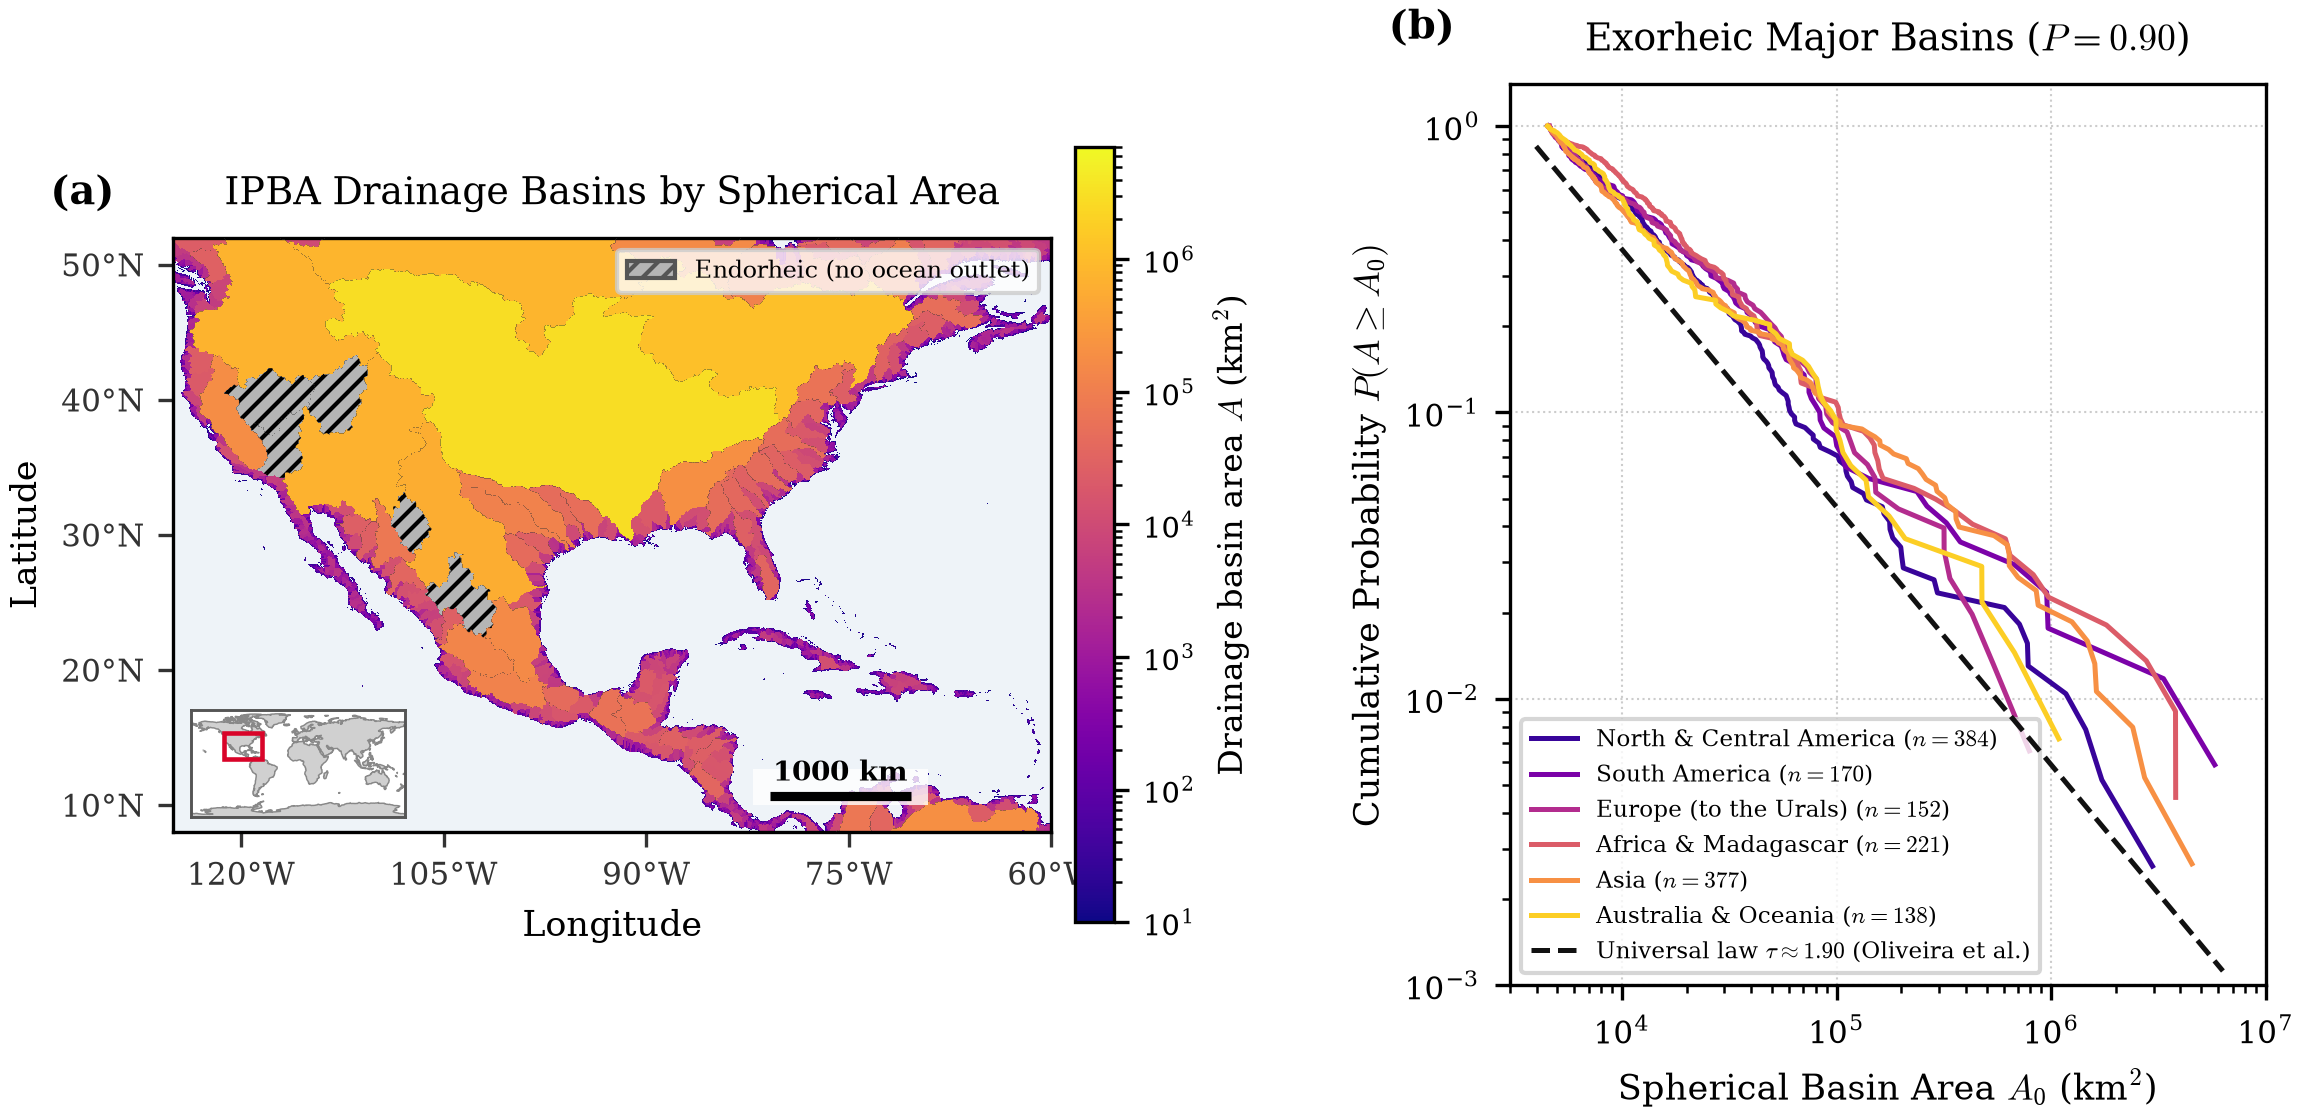

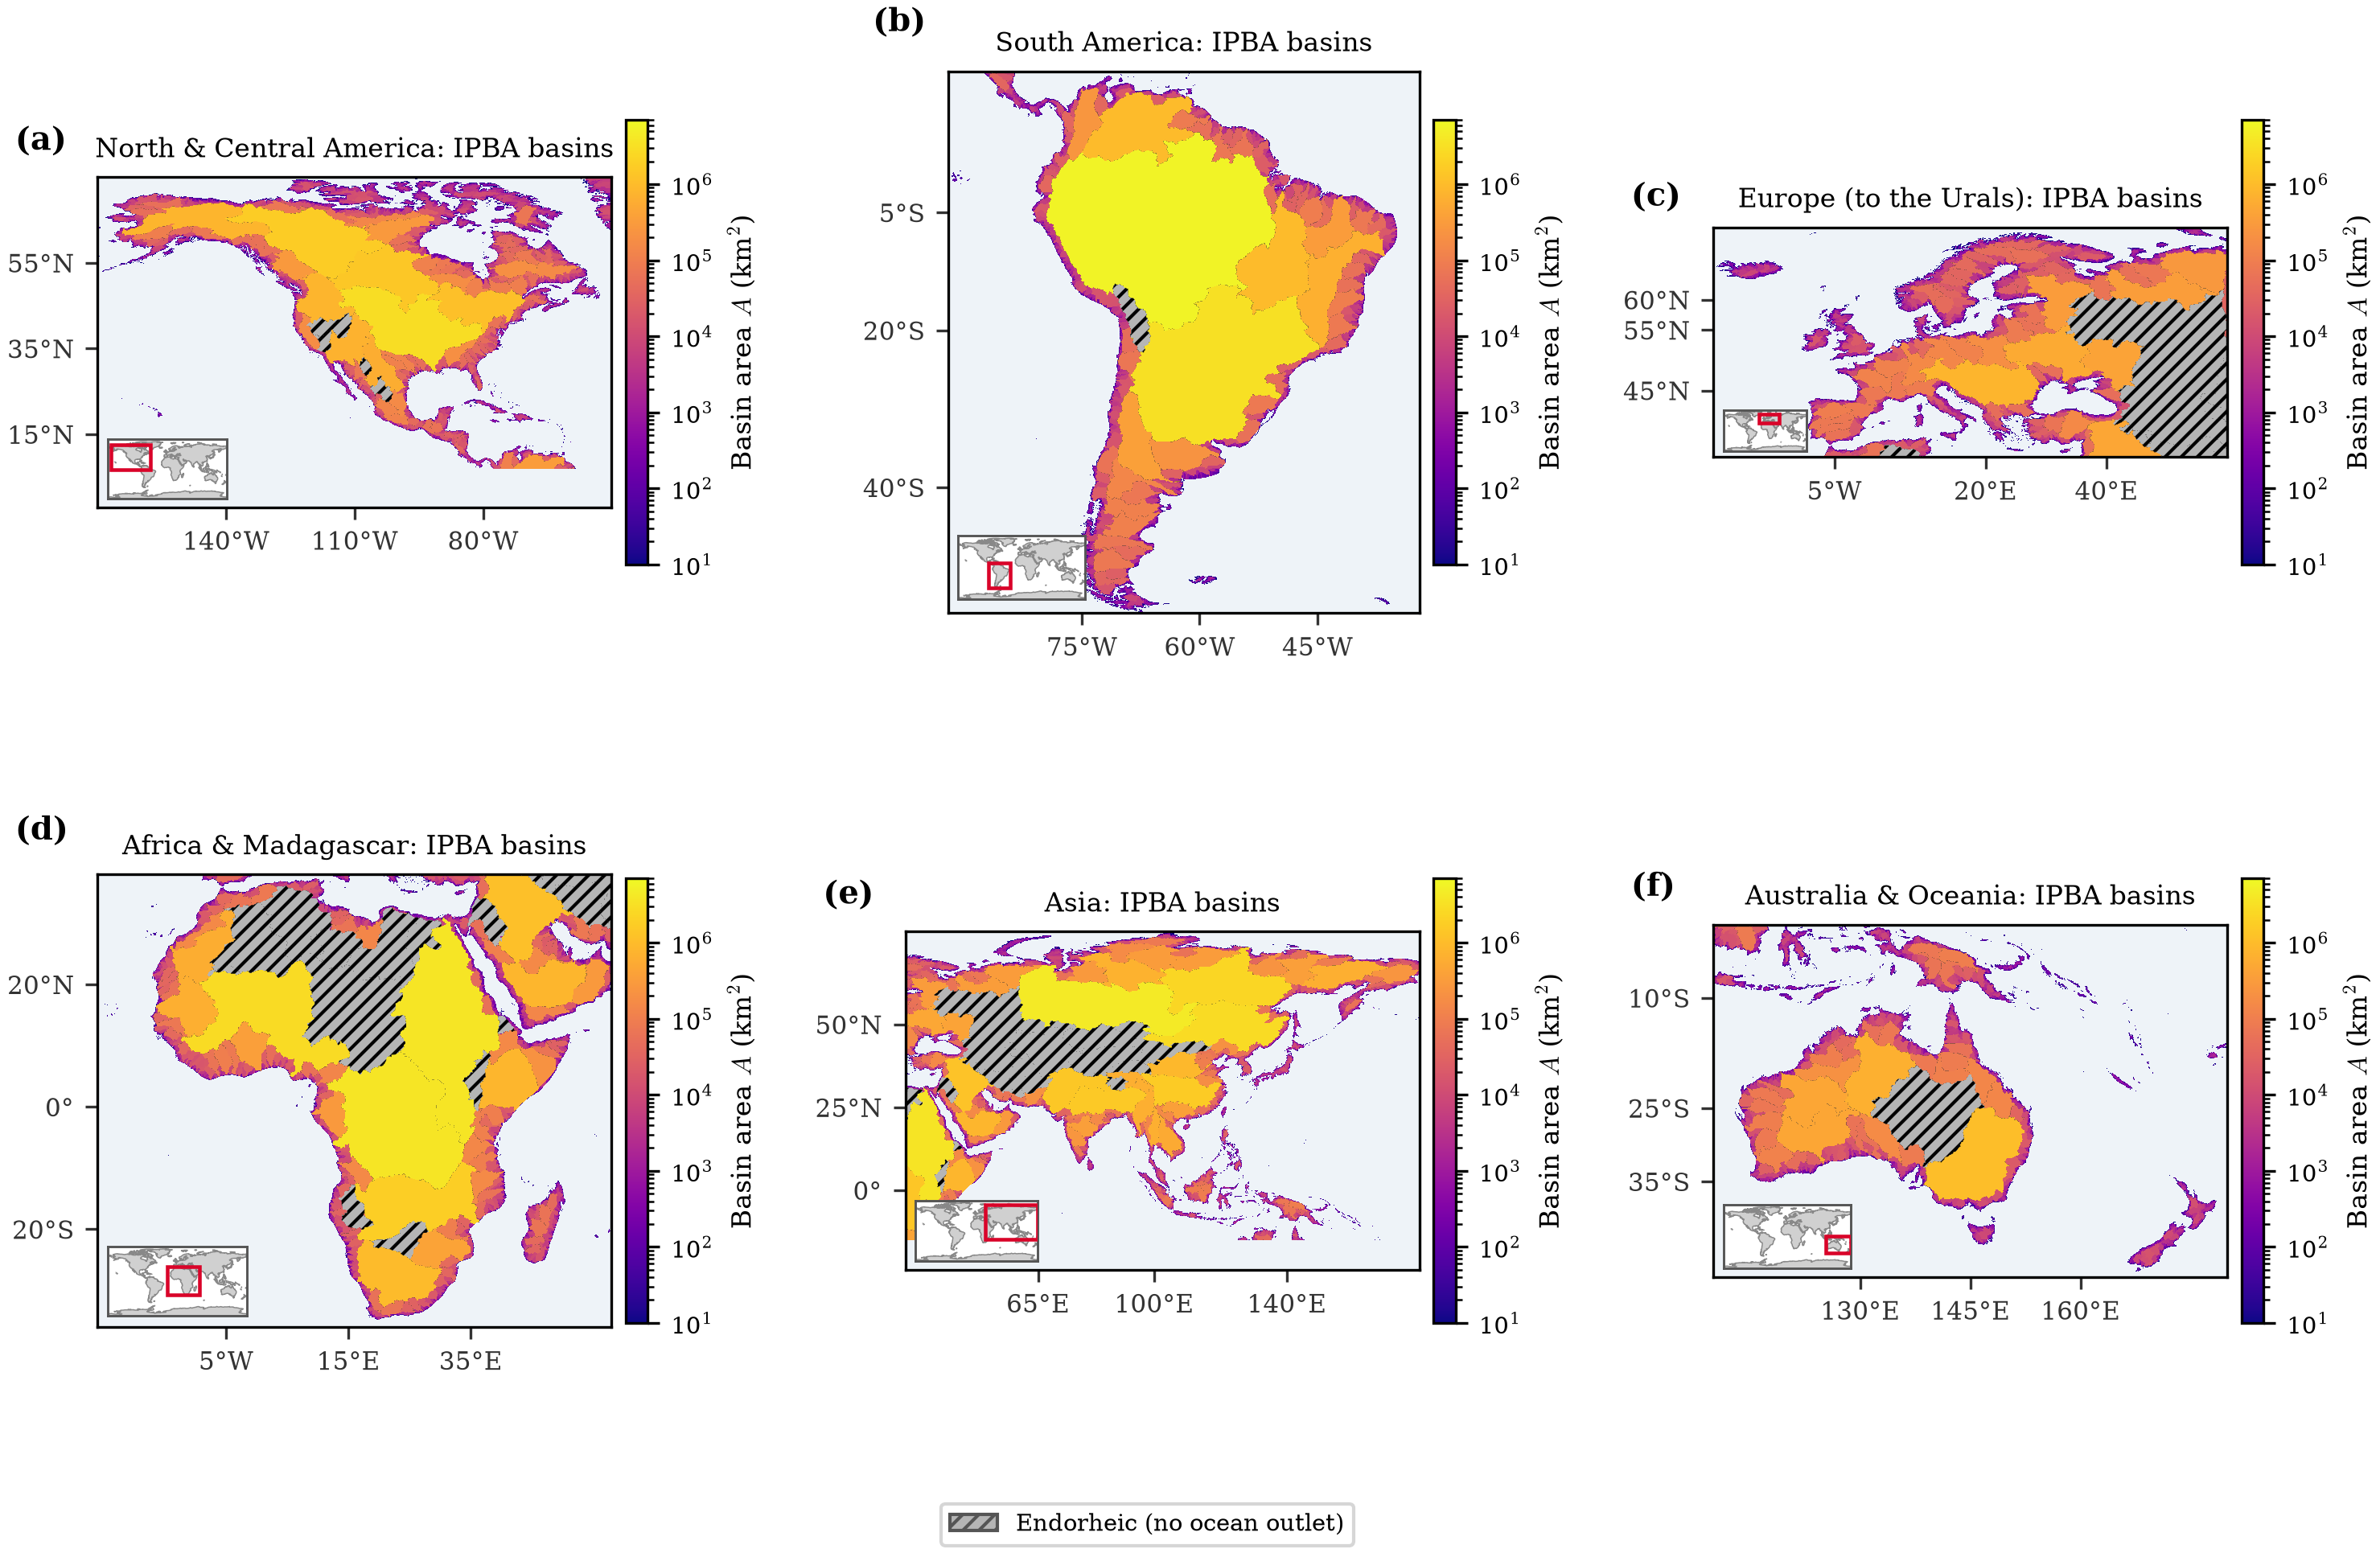

In [3]:
df_valid = pd.read_csv(RESULTS_DIR / "validacao_bacias_literatura.csv")
df_valid["desvio_%"] = 100 * df_valid["desvio_relativo"]
print(f"Bacias de referência dentro de ±20%: {int(df_valid['dentro_20pct'].sum())}/{len(df_valid)}")
display(df_valid[["bacia", "area_literatura_km2", "area_ipba_endo_km2", "desvio_%", "status"]].round(1))

# Prova de que o Nilo é uma única bacia: pontos de controle de toda a rede de drenagem caem no mesmo rótulo
info, grade = ReadGeoTiff(RESULTS_DIR / "bacias_bloco_afroeurasia_oceania_ipba.tif")
gt = info["GeoTransform"]
rotulo = lambda lon, lat: int(grade[int((lat - gt[3]) / gt[5]), int((lon - gt[0]) / gt[1])])
controle = {
    "Cairo (ápice do delta)": (31.25, 30.05), "Aswan": (32.9, 24.09), "Atbara": (33.98, 17.7),
    "Cartum (confluência)": (32.53, 15.6), "Lago Tana (Nilo Azul)": (37.3, 12.0),
    "Juba (Nilo Branco)": (31.6, 4.85), "Lago Alberto": (30.9, 1.7), "Lago Vitória (Jinja)": (33.2, 0.42),
}
df_nilo = pd.DataFrame([{"ponto": k, "lon": v[0], "lat": v[1], "rotulo_bacia": rotulo(*v)} for k, v in controle.items()])
display(df_nilo)
assert df_nilo["rotulo_bacia"].nunique() == 1 and df_nilo["rotulo_bacia"].iloc[0] > 0, "Nilo fragmentado!"
print("Nilo: bacia única e exorreica (rótulo", df_nilo["rotulo_bacia"].iloc[0], ")")

df_endo = pd.read_csv(RESULTS_DIR / "bacias_endorreicas_global.csv")
print(f"\nBacias endorreicas: {len(df_endo)} | área total {df_endo['area_km2'].sum() / 1e6:.2f} Mkm² "
      f"| população {df_endo['pop_total'].sum() / 1e6:.1f} M hab (excluída dos emissores marinhos)")
display(df_endo[["global_basin_uid", "nome_sistema_endorreico", "area_km2", "pop_total", "profundidade_m"]].head(15).round(0))
df_escala = pd.read_csv(RESULTS_DIR / "escala_pop_lixo_global.csv")
assert not df_escala["global_basin_uid"].str.contains("__E").any(), "Bacia endorreica no pareamento!"
print("Nenhuma bacia endorreica na tabela de alometria.")

sens_path = RESULTS_DIR / "sensibilidade_endorreica.csv"
if sens_path.exists():
    display(pd.read_csv(sens_path).round(1))
display(Image(filename=str(GRAFICOS_DIR / "watherSeads" / "ipba_drainage_basins_universal_scaling.png"), width=880))
display(Image(filename=str(GRAFICOS_DIR / "watherSeads" / "ipba_drainage_basins_6regions.png"), width=880))


---
## 3. Calibração Dinâmica de Zipf e CCA por Região Demográfica

A densidade GPW (contagem / área esférica) é agregada a 1'. As 6 regiões são disjuntas (`codigo_regiao`), e a população de uma bacia que cruza regiões é somada. A matriz $(D, L)$ completa de cada região fica salva em `zipf_matriz_<regiao>.npz`. As faixas com $L < L_{\min}$ (diagonal do pixel) são inadmissíveis.

> A animação do CCA até o $(D^*, L^*)$ calibrado da América do Norte está em `geracao_graficos/gifs/cca_urban_clustering_evolution.gif`.


,nome_en,D_star_hab_km2,l_metros,L_MIN_metros,alpha_ols_100,r2_ols_100,restricao_r2_atendida,alpha_100,alpha_csn,n_manchas,maior_mancha_hab,pop_total_hab,n_manchas_divididas_entre_bacias
0,North & Central America and Caribbean,100,4000,2700,0.997,0.986,True,1.055,1.368,15348,4.962661e+07,6.193595e+08,853
1,South America,100,5000,2700,1.000,0.982,True,1.087,1.276,9598,2.856926e+07,4.586041e+08,501
2,Europe (to the Urals),100,2500,2500,0.999,0.989,True,1.115,1.210,9712,9.739167e+07,7.212596e+08,1389
3,Africa and Madagascar,300,3500,2700,1.145,0.987,True,1.186,1.211,3081,8.887669e+07,1.364944e+09,366
4,"Asia (Siberia, Middle East, India and SE Asia)",700,3500,2700,0.999,0.988,True,0.998,1.230,4001,6.249289e+08,4.767092e+09,888
5,"Australia, New Zealand and Oceania",700,3000,2700,1.232,0.983,True,1.244,1.155,352,3.652953e+06,3.742729e+07,92


Nota Oceania: A Austrália concentra a população em 5 capitais costeiras (Sydney, Melbourne, Brisbane, Perth, Adelaide) com interior desértico; a curva rank-tamanho é mais íngreme que Zipf (alpha > 1), fenômeno de macrocefalia urbana documentado na literatura.


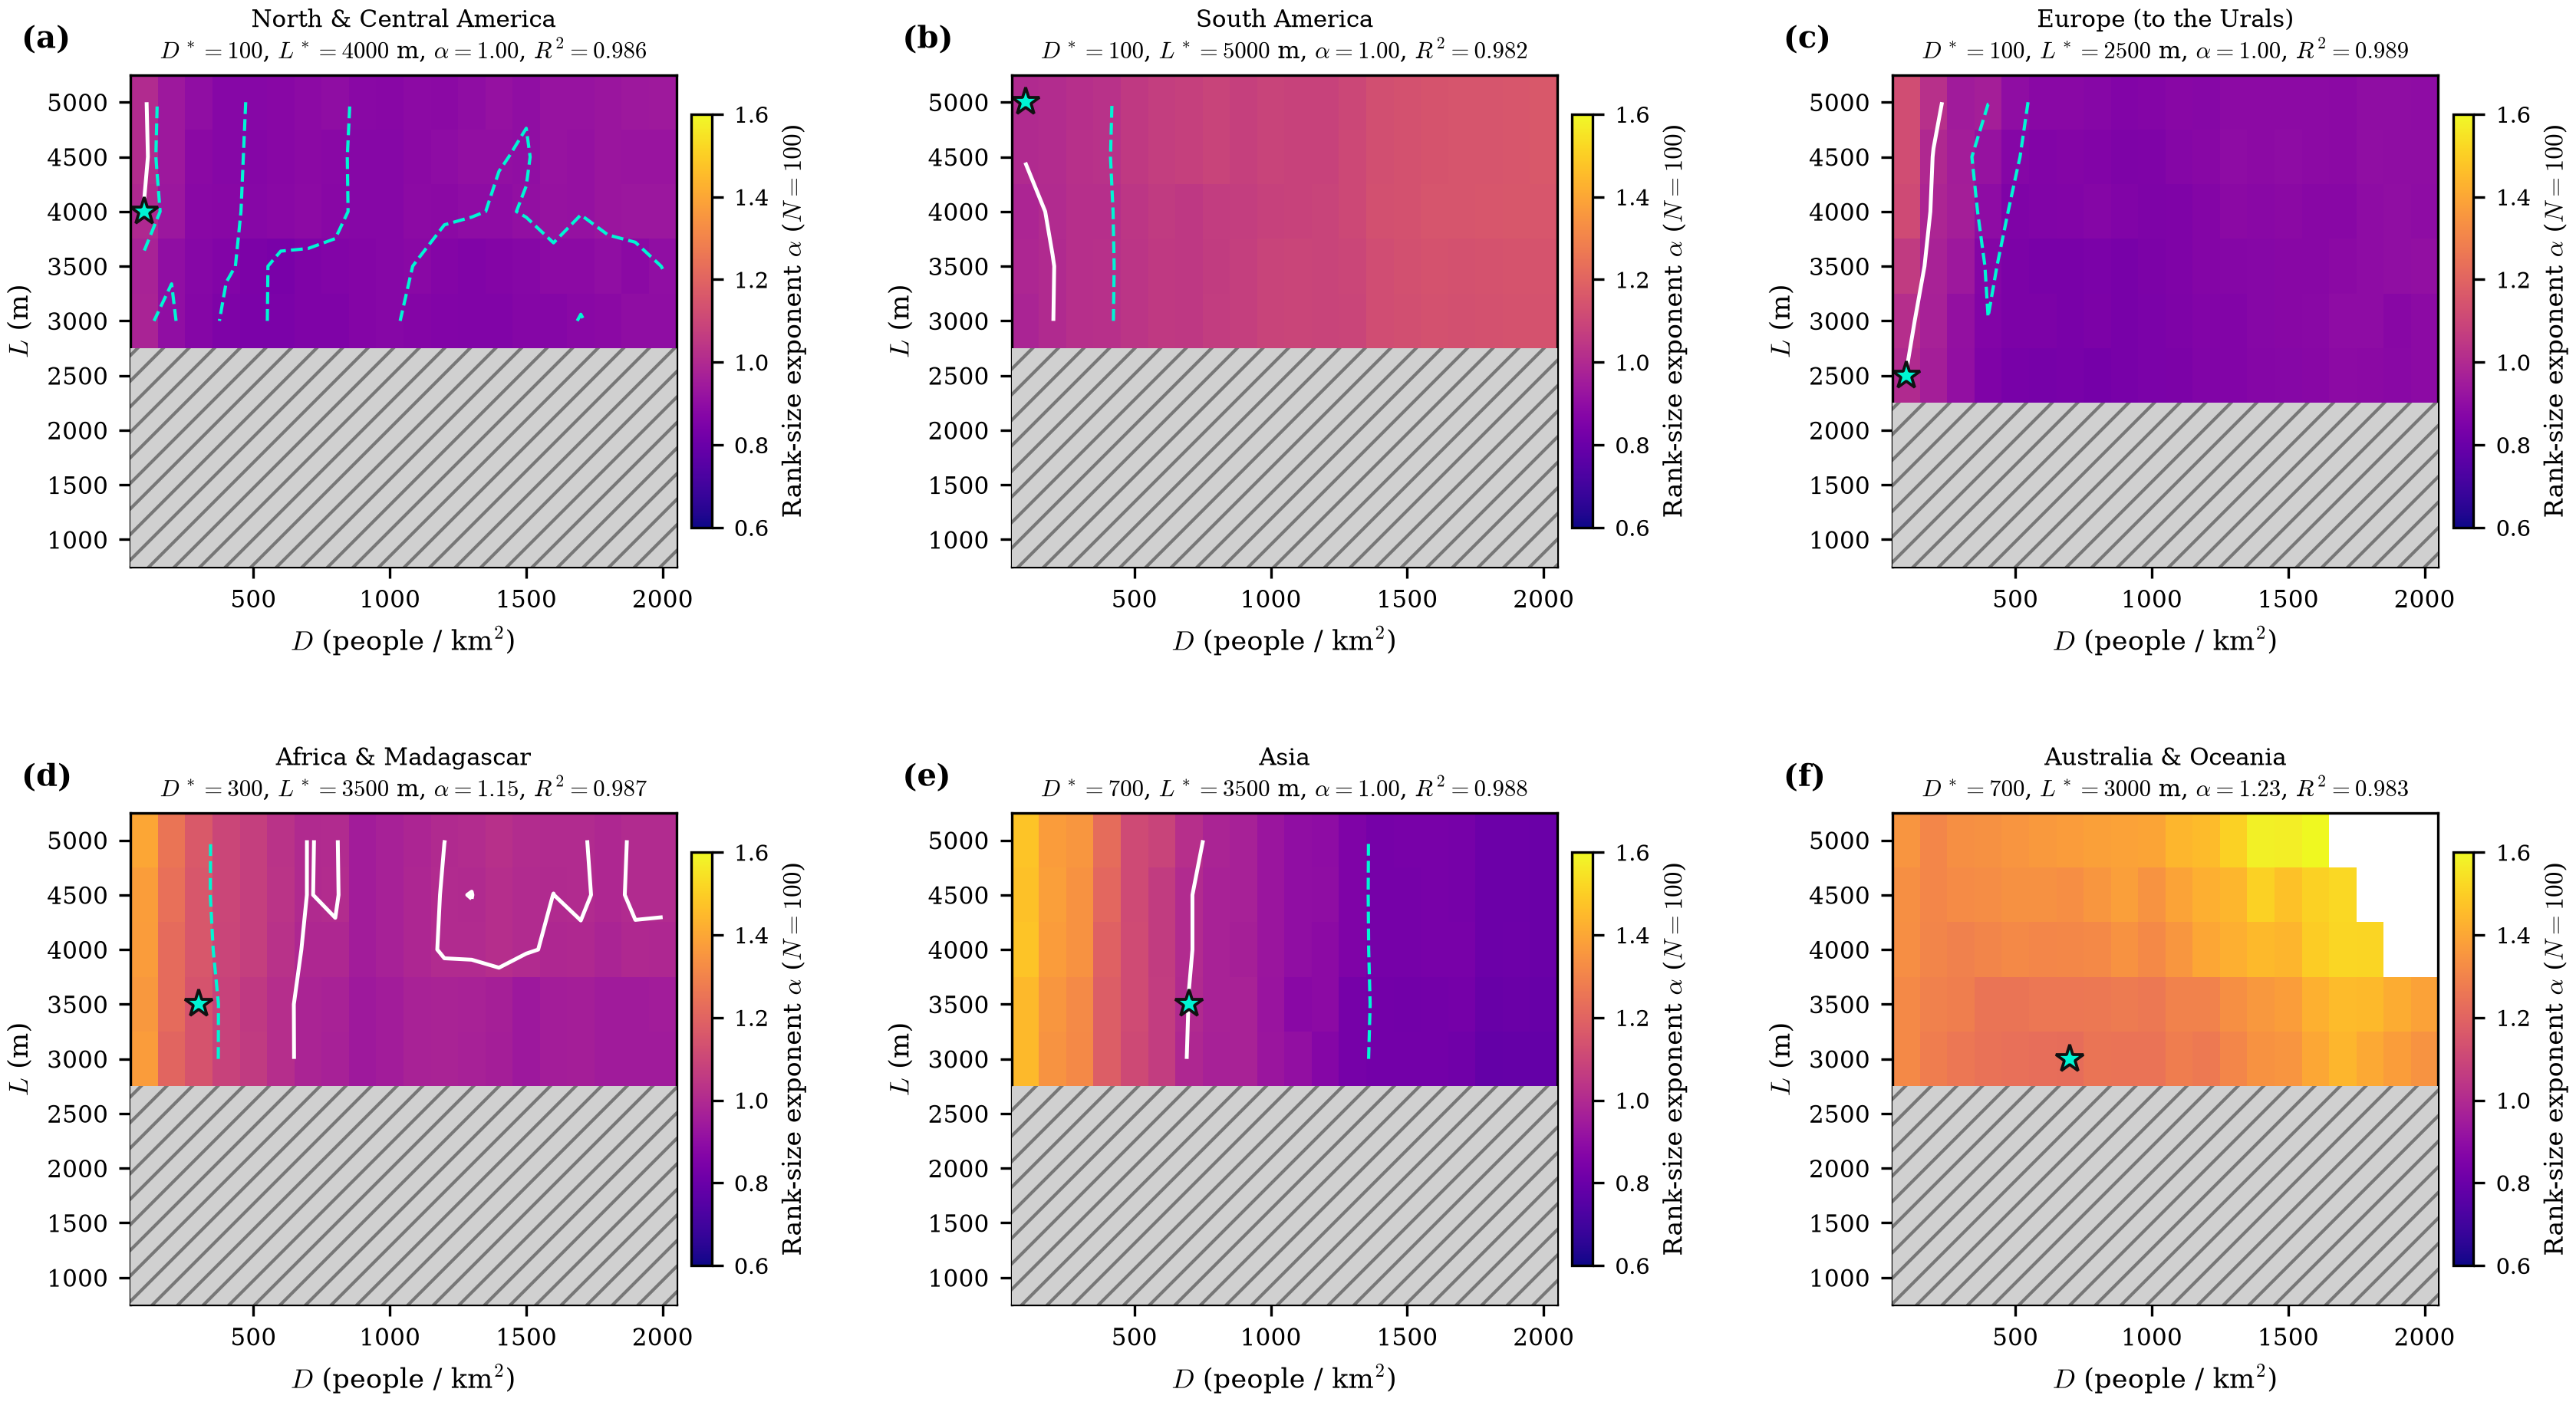

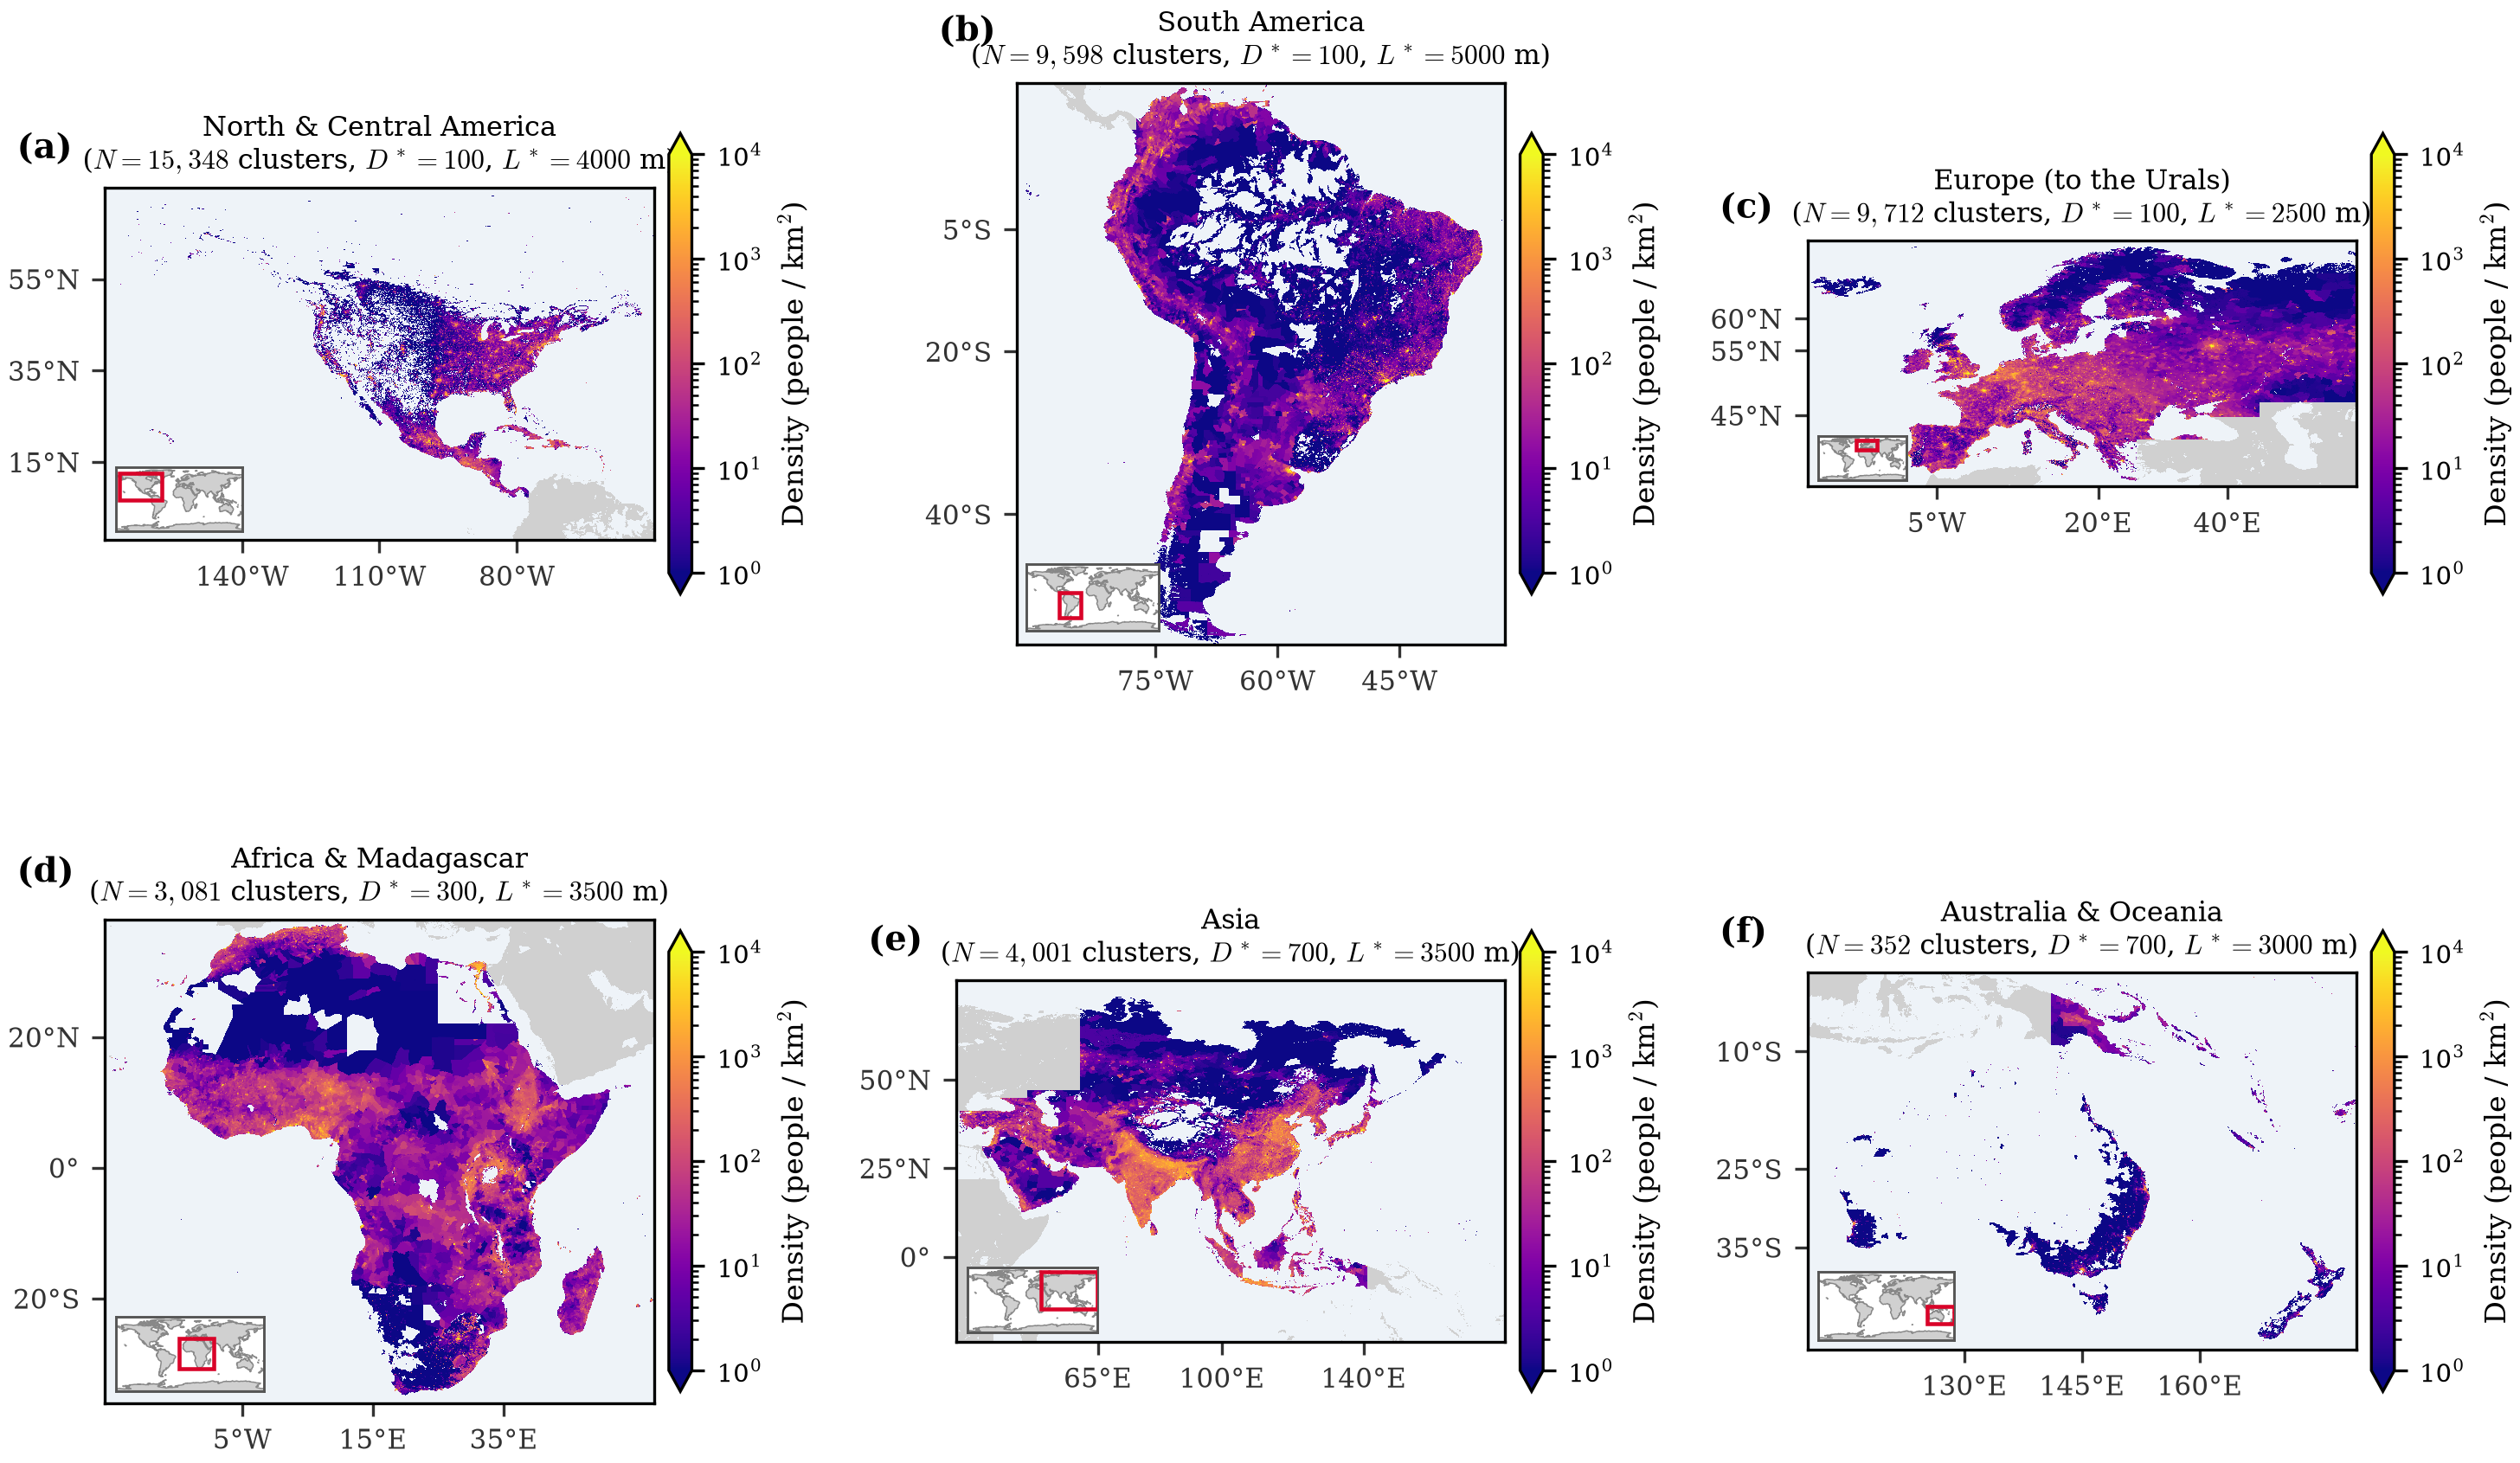

In [4]:
df_cal = pd.read_csv(RESULTS_DIR / "cca_calibracao_global_resumo.csv")
display(df_cal[[
    "nome_en", "D_star_hab_km2", "l_metros", "L_MIN_metros", "alpha_ols_100", "r2_ols_100",
    "restricao_r2_atendida", "alpha_100", "alpha_csn", "n_manchas", "maior_mancha_hab",
    "pop_total_hab", "n_manchas_divididas_entre_bacias",
]].round(3))
with open(RESULTS_DIR / "cca_calibracao_oceania_australia.json", "r", encoding="utf-8") as f:
    cal_oce = json.load(f)
print("Nota Oceania:", cal_oce.get("nota_macrocefalia", "-"))
display(Image(filename=str(GRAFICOS_DIR / "zipf" / "zipf_calibration_6regions.png"), width=880))
display(Image(filename=str(GRAFICOS_DIR / "populacao" / "population_cca_6regions.png"), width=880))


---
## 4. NOAA Costeira (GeoJSON) e Acoplamento Bacia–Cidade

`dados/ingestao_noaa_geojson.py` padroniza o GeoJSON do NCEI Microplastics Hub: `Latitude__degree_`→`lat`, `Longitude_degree_`→`lon`, `Medium`→`meio`, `Unit`→`unidade` e `medida` = `Microplastics_measurement`, preenchida com `Standardized_Nurdle__Amount`. As amostras `Ocean water` (arrastos pelágicos) são removidas.


{
  "n_total": 29076,
  "n_ocean_water": 16988,
  "n_costeiro": 12088,
  "por_meio": {
    "Nurdle Patrol": 10615,
    "Beach": 893,
    "Ocean sediment": 580
  },
  "por_unidade": {
    "pieces/10 mins": 10615,
    "pieces/m3": 893,
    "pieces kg-1 d.w.": 580
  }
}


,territorio_id,n_grandes_bacias_p90,maior_bacia_km2,area_total_km2,pop_total,pop_urbana,n_manchas
0,africa_madagascar,221,3801843.0,21928980.0,1.043765e+09,4.362087e+08,2669
1,america_do_sul,170,5779262.0,16532193.0,3.363392e+08,2.456156e+08,8664
2,americas_norte_central_caribe,384,2963121.0,19513605.0,4.538011e+08,3.794877e+08,13858
3,asia_continental_arquipelagos,377,4524536.0,31301309.0,3.519277e+09,1.763773e+09,2535
4,europa_mediterraneo,152,790774.0,6588460.0,4.981257e+08,3.727725e+08,5757
5,oceania_australia,138,1084597.0,6150659.0,1.542608e+07,5.694704e+06,155


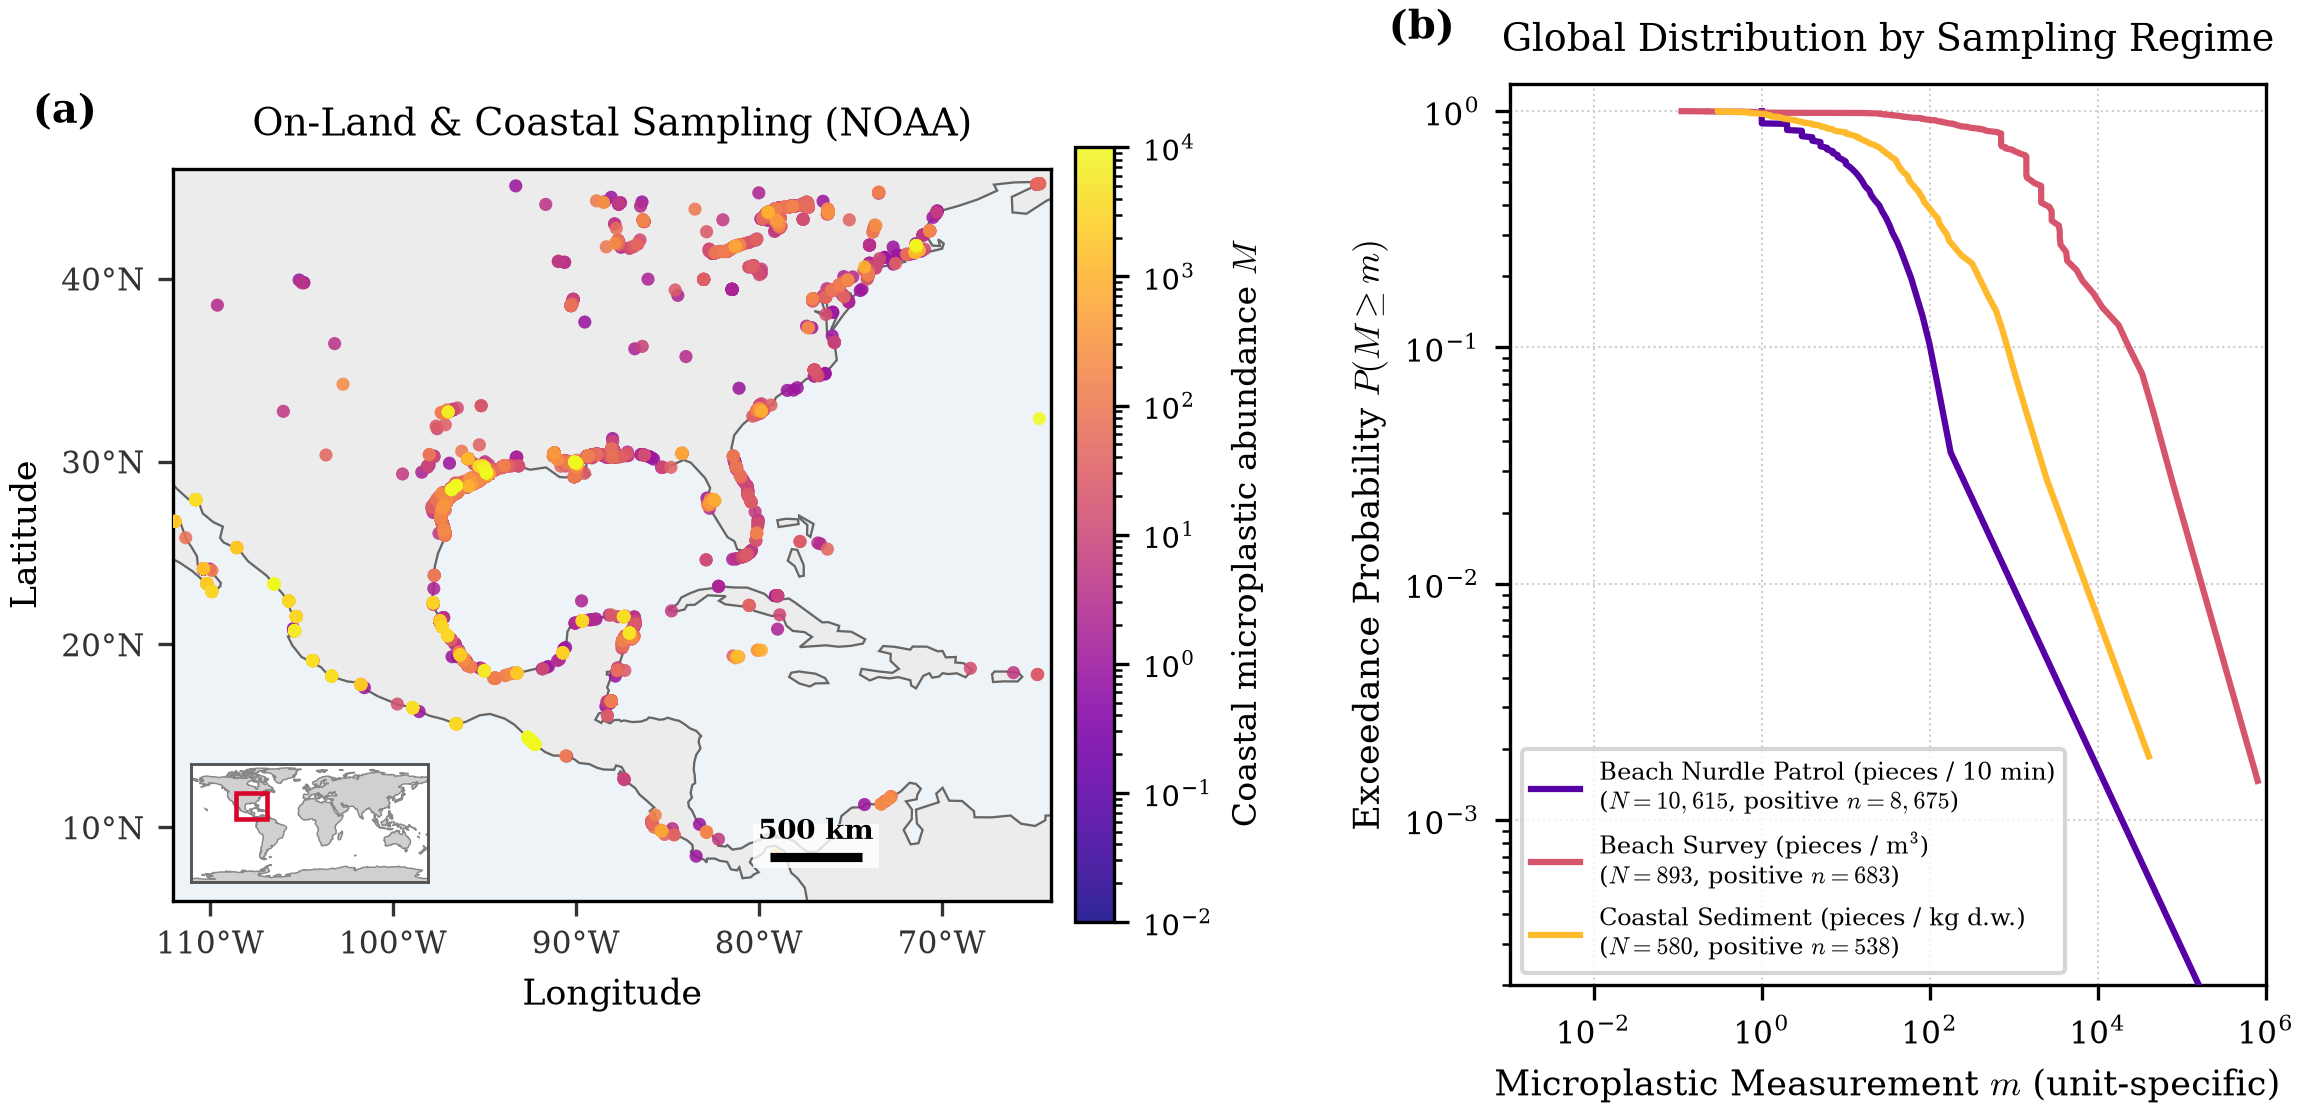

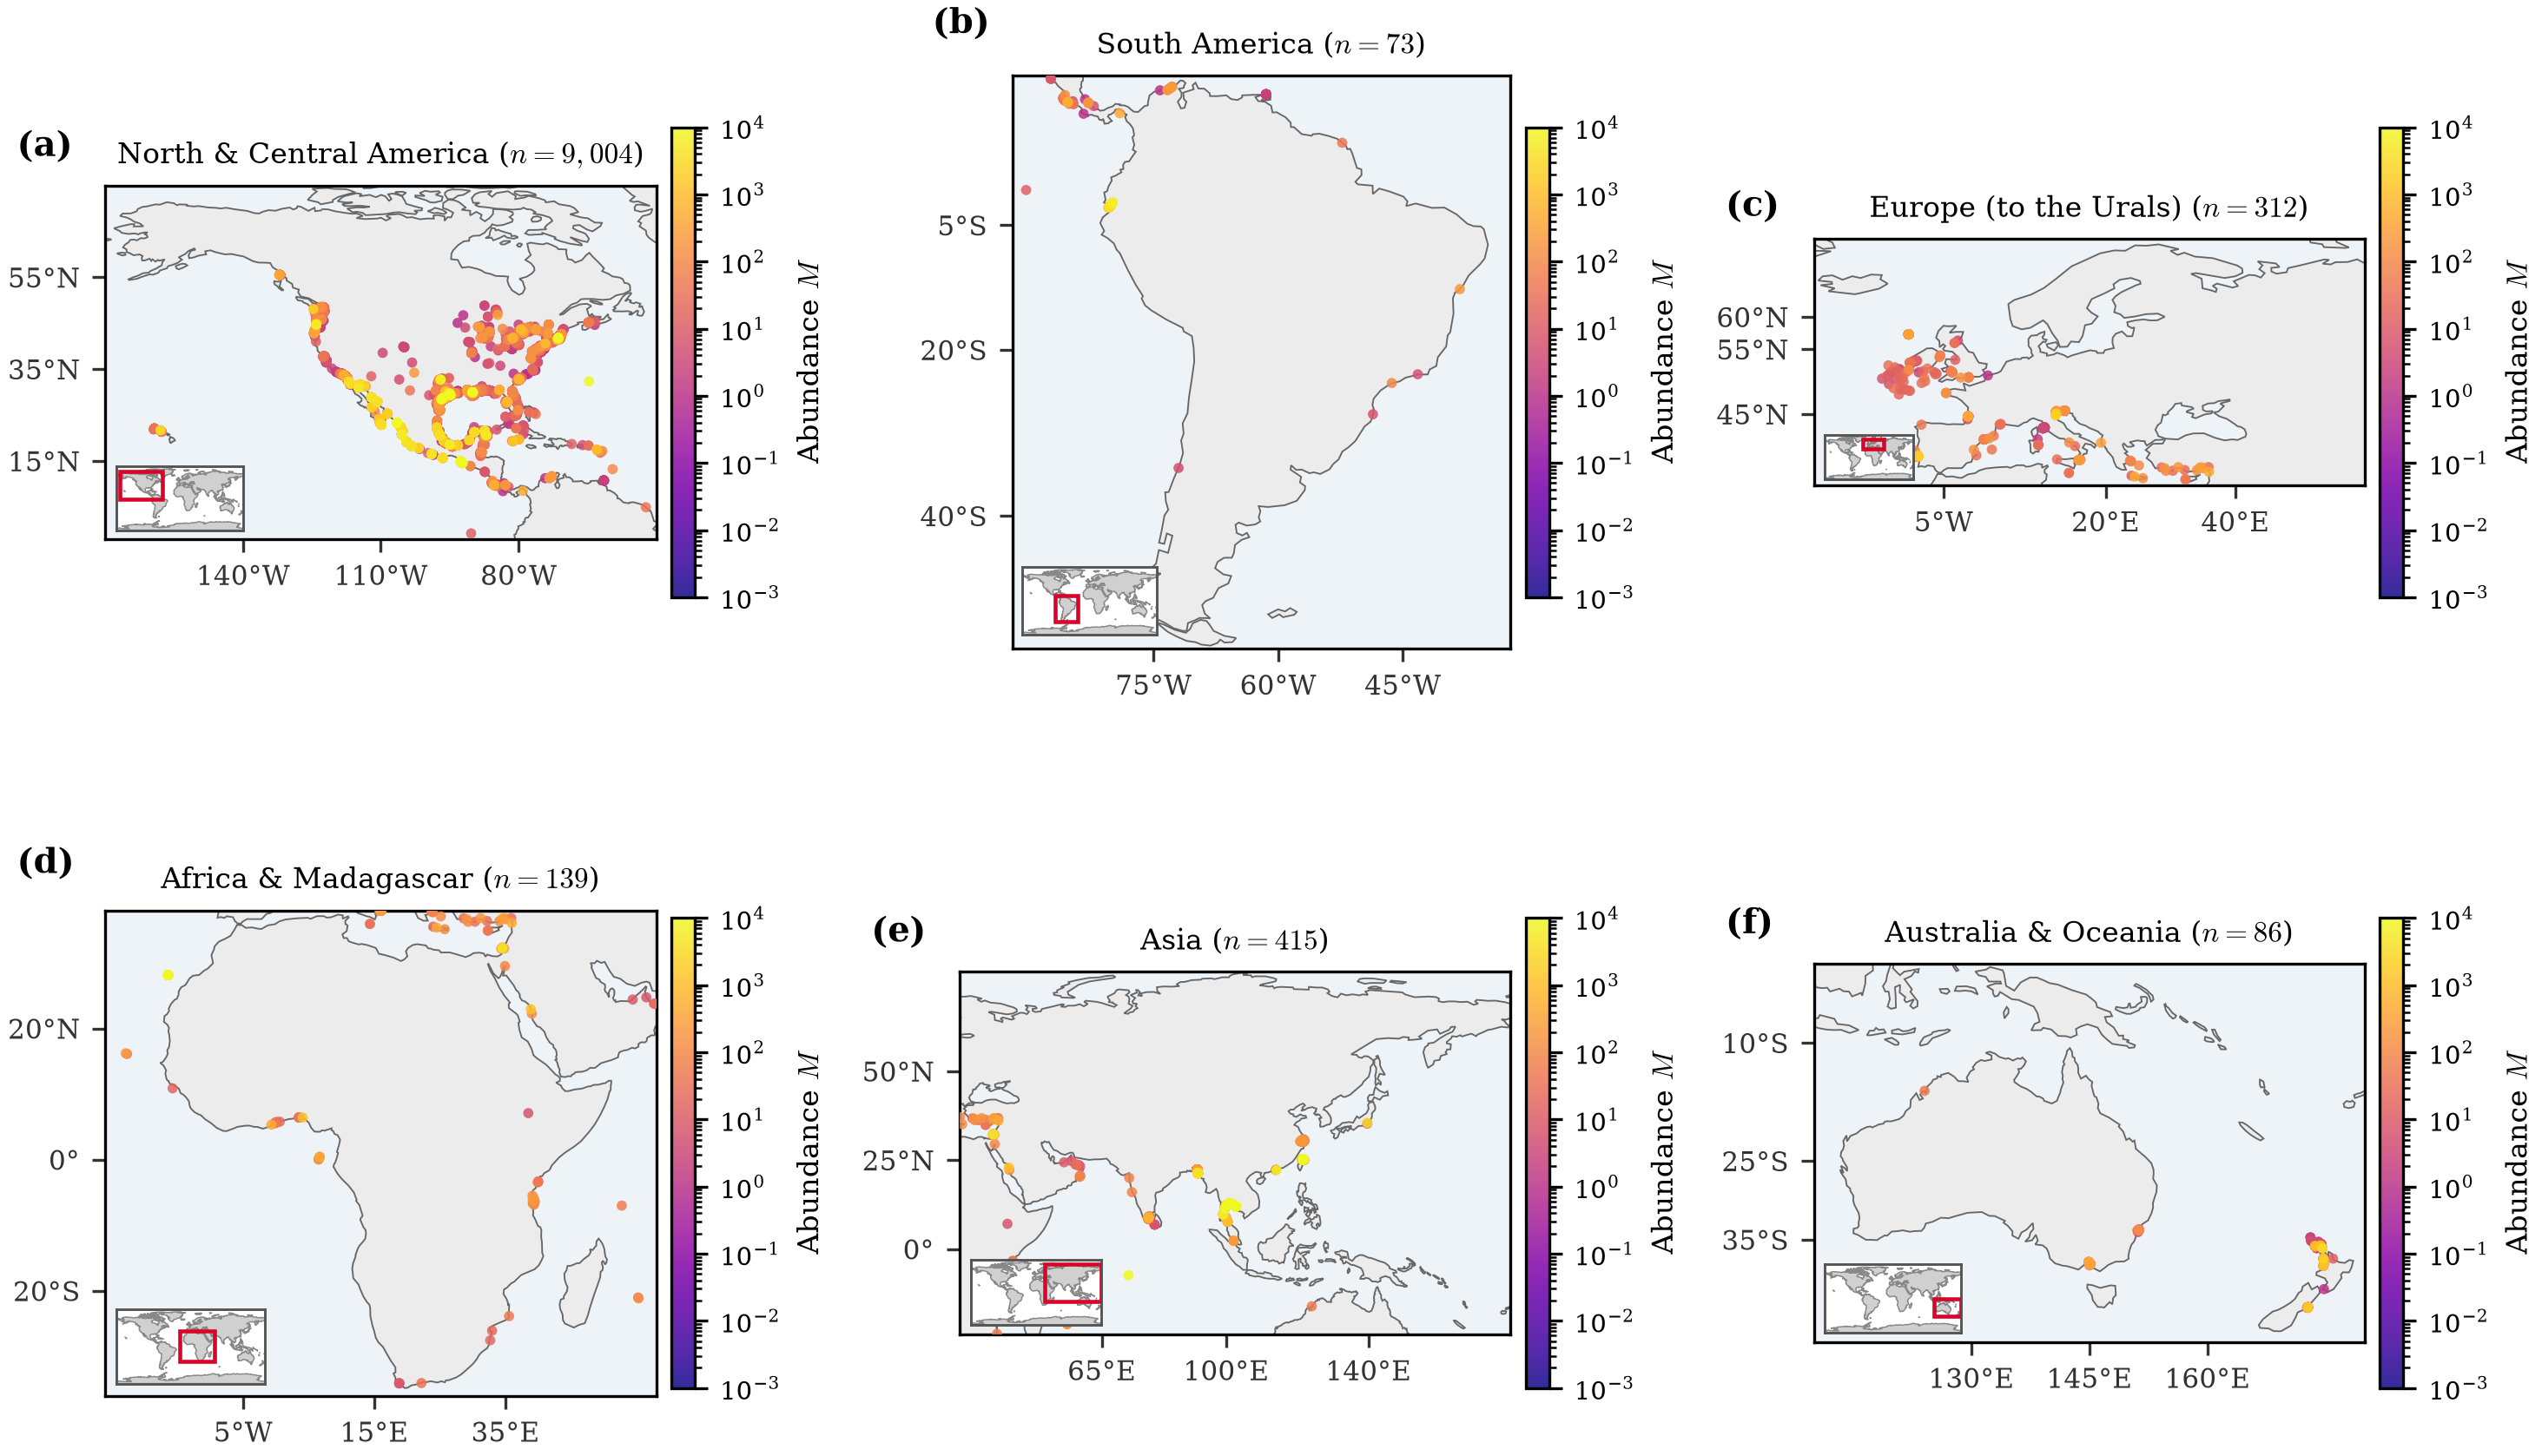

In [5]:
with open(REPO_ROOT / "dados" / "noaa_microplastics.resumo.json", "r", encoding="utf-8") as f:
    resumo_noaa = json.load(f)
print(json.dumps(resumo_noaa, indent=2, ensure_ascii=False))

df_bacias = pd.read_csv(RESULTS_DIR / "bacias_global_consolidado.csv")
exo = df_bacias[~df_bacias["is_endorheic"]]
display(exo.groupby("territorio_id", as_index=False).agg(
    n_grandes_bacias_p90=("basin_id", "count"),
    maior_bacia_km2=("area_km2", "max"),
    area_total_km2=("area_km2", "sum"),
    pop_total=("pop_total", "sum"),
    pop_urbana=("pop_urbana", "sum"),
    n_manchas=("n_manchas_na_bacia", "sum"),
).round(0))
display(Image(filename=str(GRAFICOS_DIR / "noaa" / "noaa_global_microplastic_regimes.png"), width=880))
display(Image(filename=str(GRAFICOS_DIR / "noaa" / "noaa_sampling_6regions.png"), width=880))


---
## 5. Alometria $(M \times A) \propto P^\beta$ e Comparação de Cenários

Entram apenas as grandes bacias exorreicas cuja foz tem estação costeira real a $\leq R$ km (uma bacia por site). Para combinar regimes, cada métrica é dividida pela mediana do seu regime.


,regime,raio,n,beta_conc,r_conc,beta_MxA,ic95_MxA,r_MxA,p_r_MxA,rho_MxA,p_perm_MxA
0,nurdle_10min,R_15km,46,0.2527,0.2190,0.5179,"[0.19, 0.90]",0.3531,0.0161,0.3759,0.0174
1,nurdle_10min,R_25km,56,0.2621,0.2672,0.5956,"[0.33, 0.93]",0.4596,0.0004,0.4573,0.0005
2,nurdle_10min,R_38km,63,0.2547,0.2654,0.6519,"[0.35, 1.01]",0.4852,0.0001,0.4506,0.0002
3,nurdle_10min,R_50km,72,0.1730,0.1865,0.5323,"[0.25, 0.83]",0.4187,0.0003,0.3526,0.0005
4,water_m3,R_15km,16,0.0470,0.0695,0.3811,"[-0.15, 1.22]",0.4207,0.1049,0.4559,0.1031
5,water_m3,R_25km,24,0.0720,0.1053,0.3441,"[-0.03, 0.82]",0.3994,0.0533,0.3704,0.0523
6,water_m3,R_38km,30,0.0251,0.0343,0.3743,"[-0.00, 0.78]",0.3967,0.0300,0.2925,0.0302
7,water_m3,R_50km,35,0.0207,0.0261,0.4030,"[0.05, 0.79]",0.4092,0.0147,0.3244,0.0153
8,sediment_kg,R_15km,6,-0.1764,-0.1642,0.0071,"[-0.73, 8.39]",0.0050,0.9926,-0.2000,0.9952
9,sediment_kg,R_25km,9,-0.2014,-0.2267,0.2151,"[-0.32, 2.16]",0.1708,0.6609,0.1833,0.6355


Combinado global (R <= 25 km, (M x A) normalizado pela mediana vs P_total):


,cenario,n,beta,ic95_inf,ic95_sup,r,p_r,rho,p_rho,r2,p_perm
0,A_baseline_v1,51,0.3859,0.1588,0.6560,0.4083,0.0029,0.4208,0.0021,0.1667,0.0035
1,B_hidrologia_v2_noaa_legado,54,0.4123,0.2118,0.6781,0.3995,0.0028,0.4664,0.0004,0.1596,0.0030
2,C_hidrologia_v2_noaa_nova,81,0.4500,0.2348,0.7193,0.3829,0.0004,0.4073,0.0002,0.1466,0.0002


Bacias novas com coleta: {'vs_B_noaa_legado': 30, 'vs_A_baseline_v1': 39}

América do Norte/Central, Nurdle Patrol, R <= 25 km (n = 44): beta = 0.556 [0.233, 0.975] | r = 0.421 (p = 4.5e-03)
Leave-one-out: r em [0.357, 0.467]


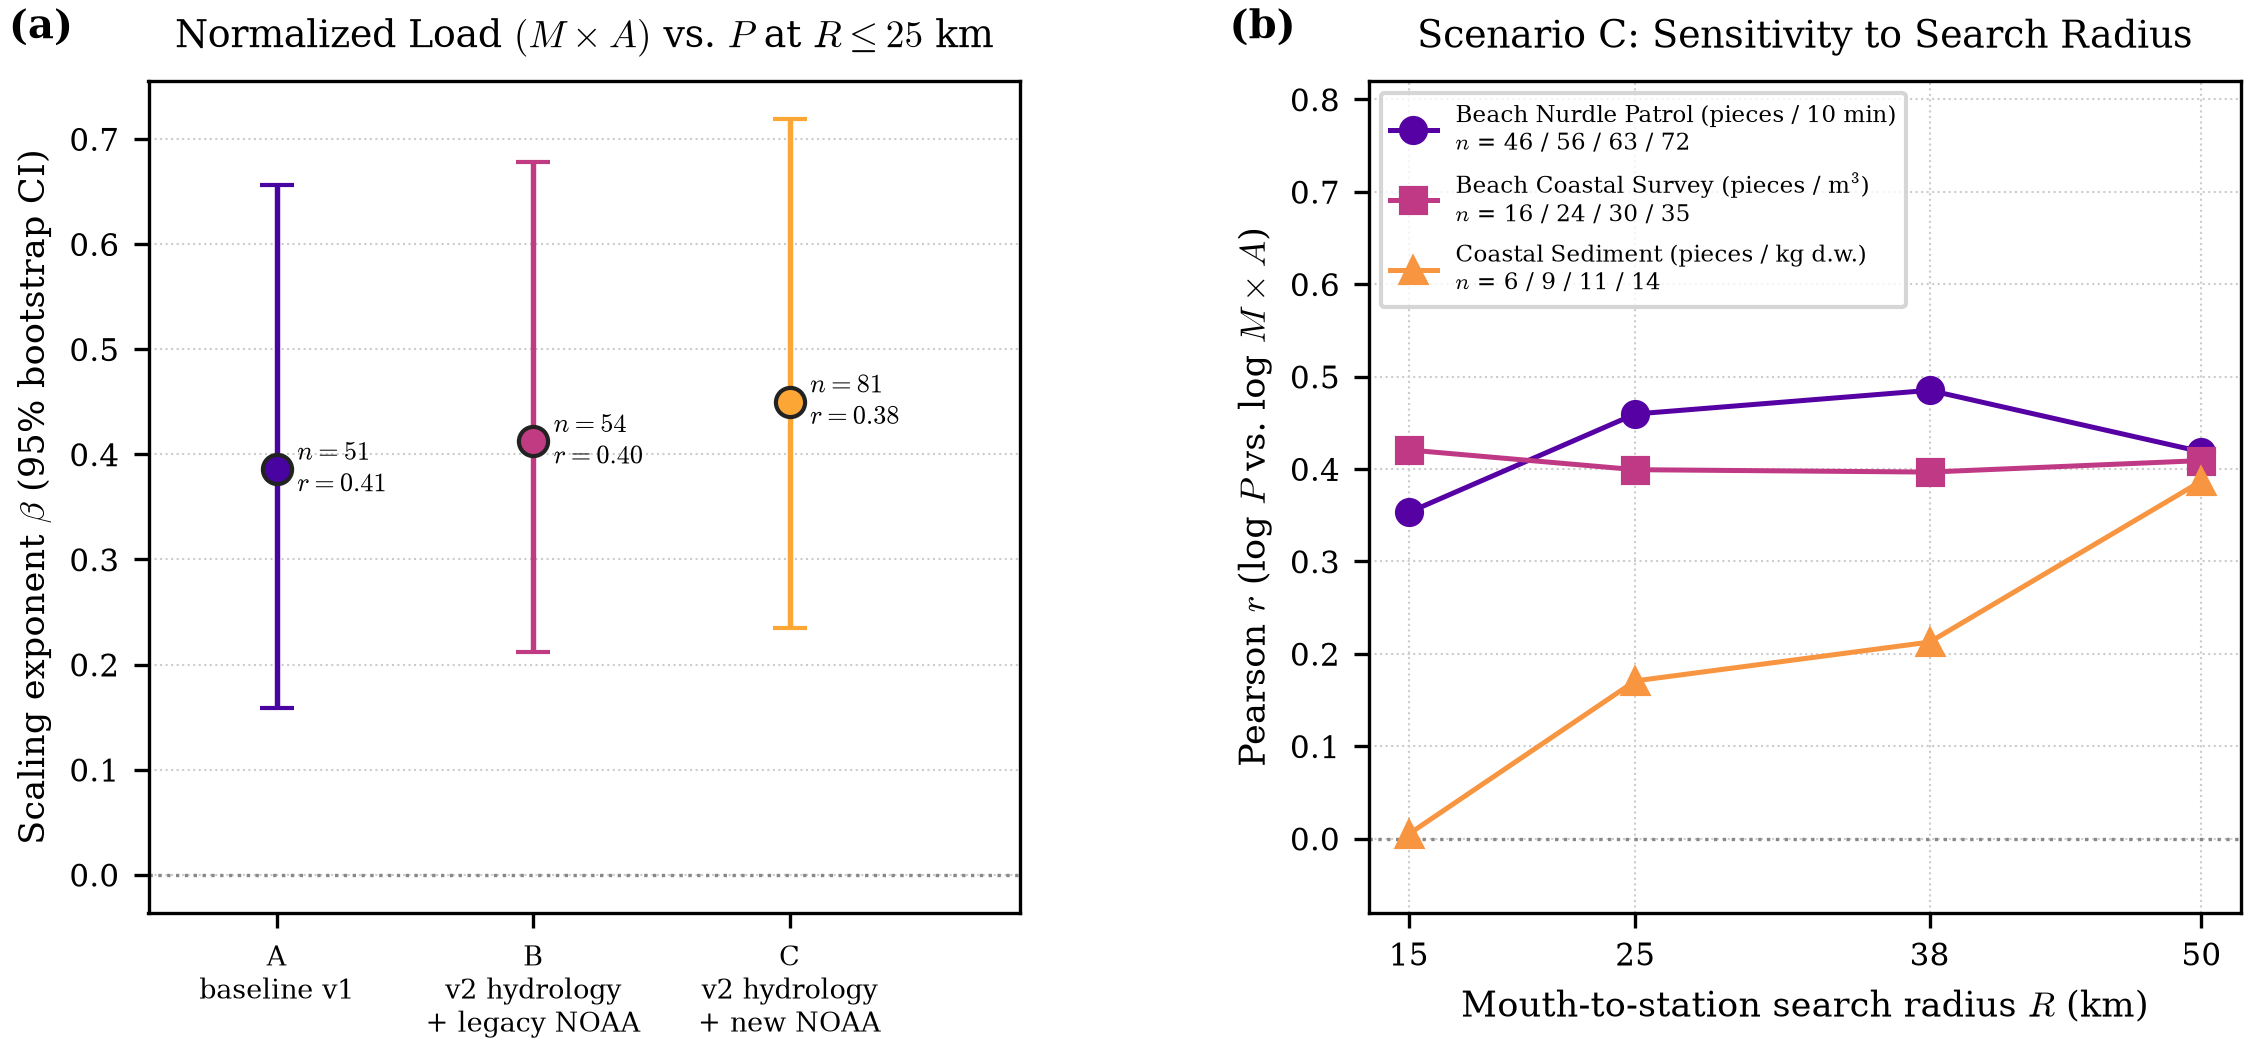

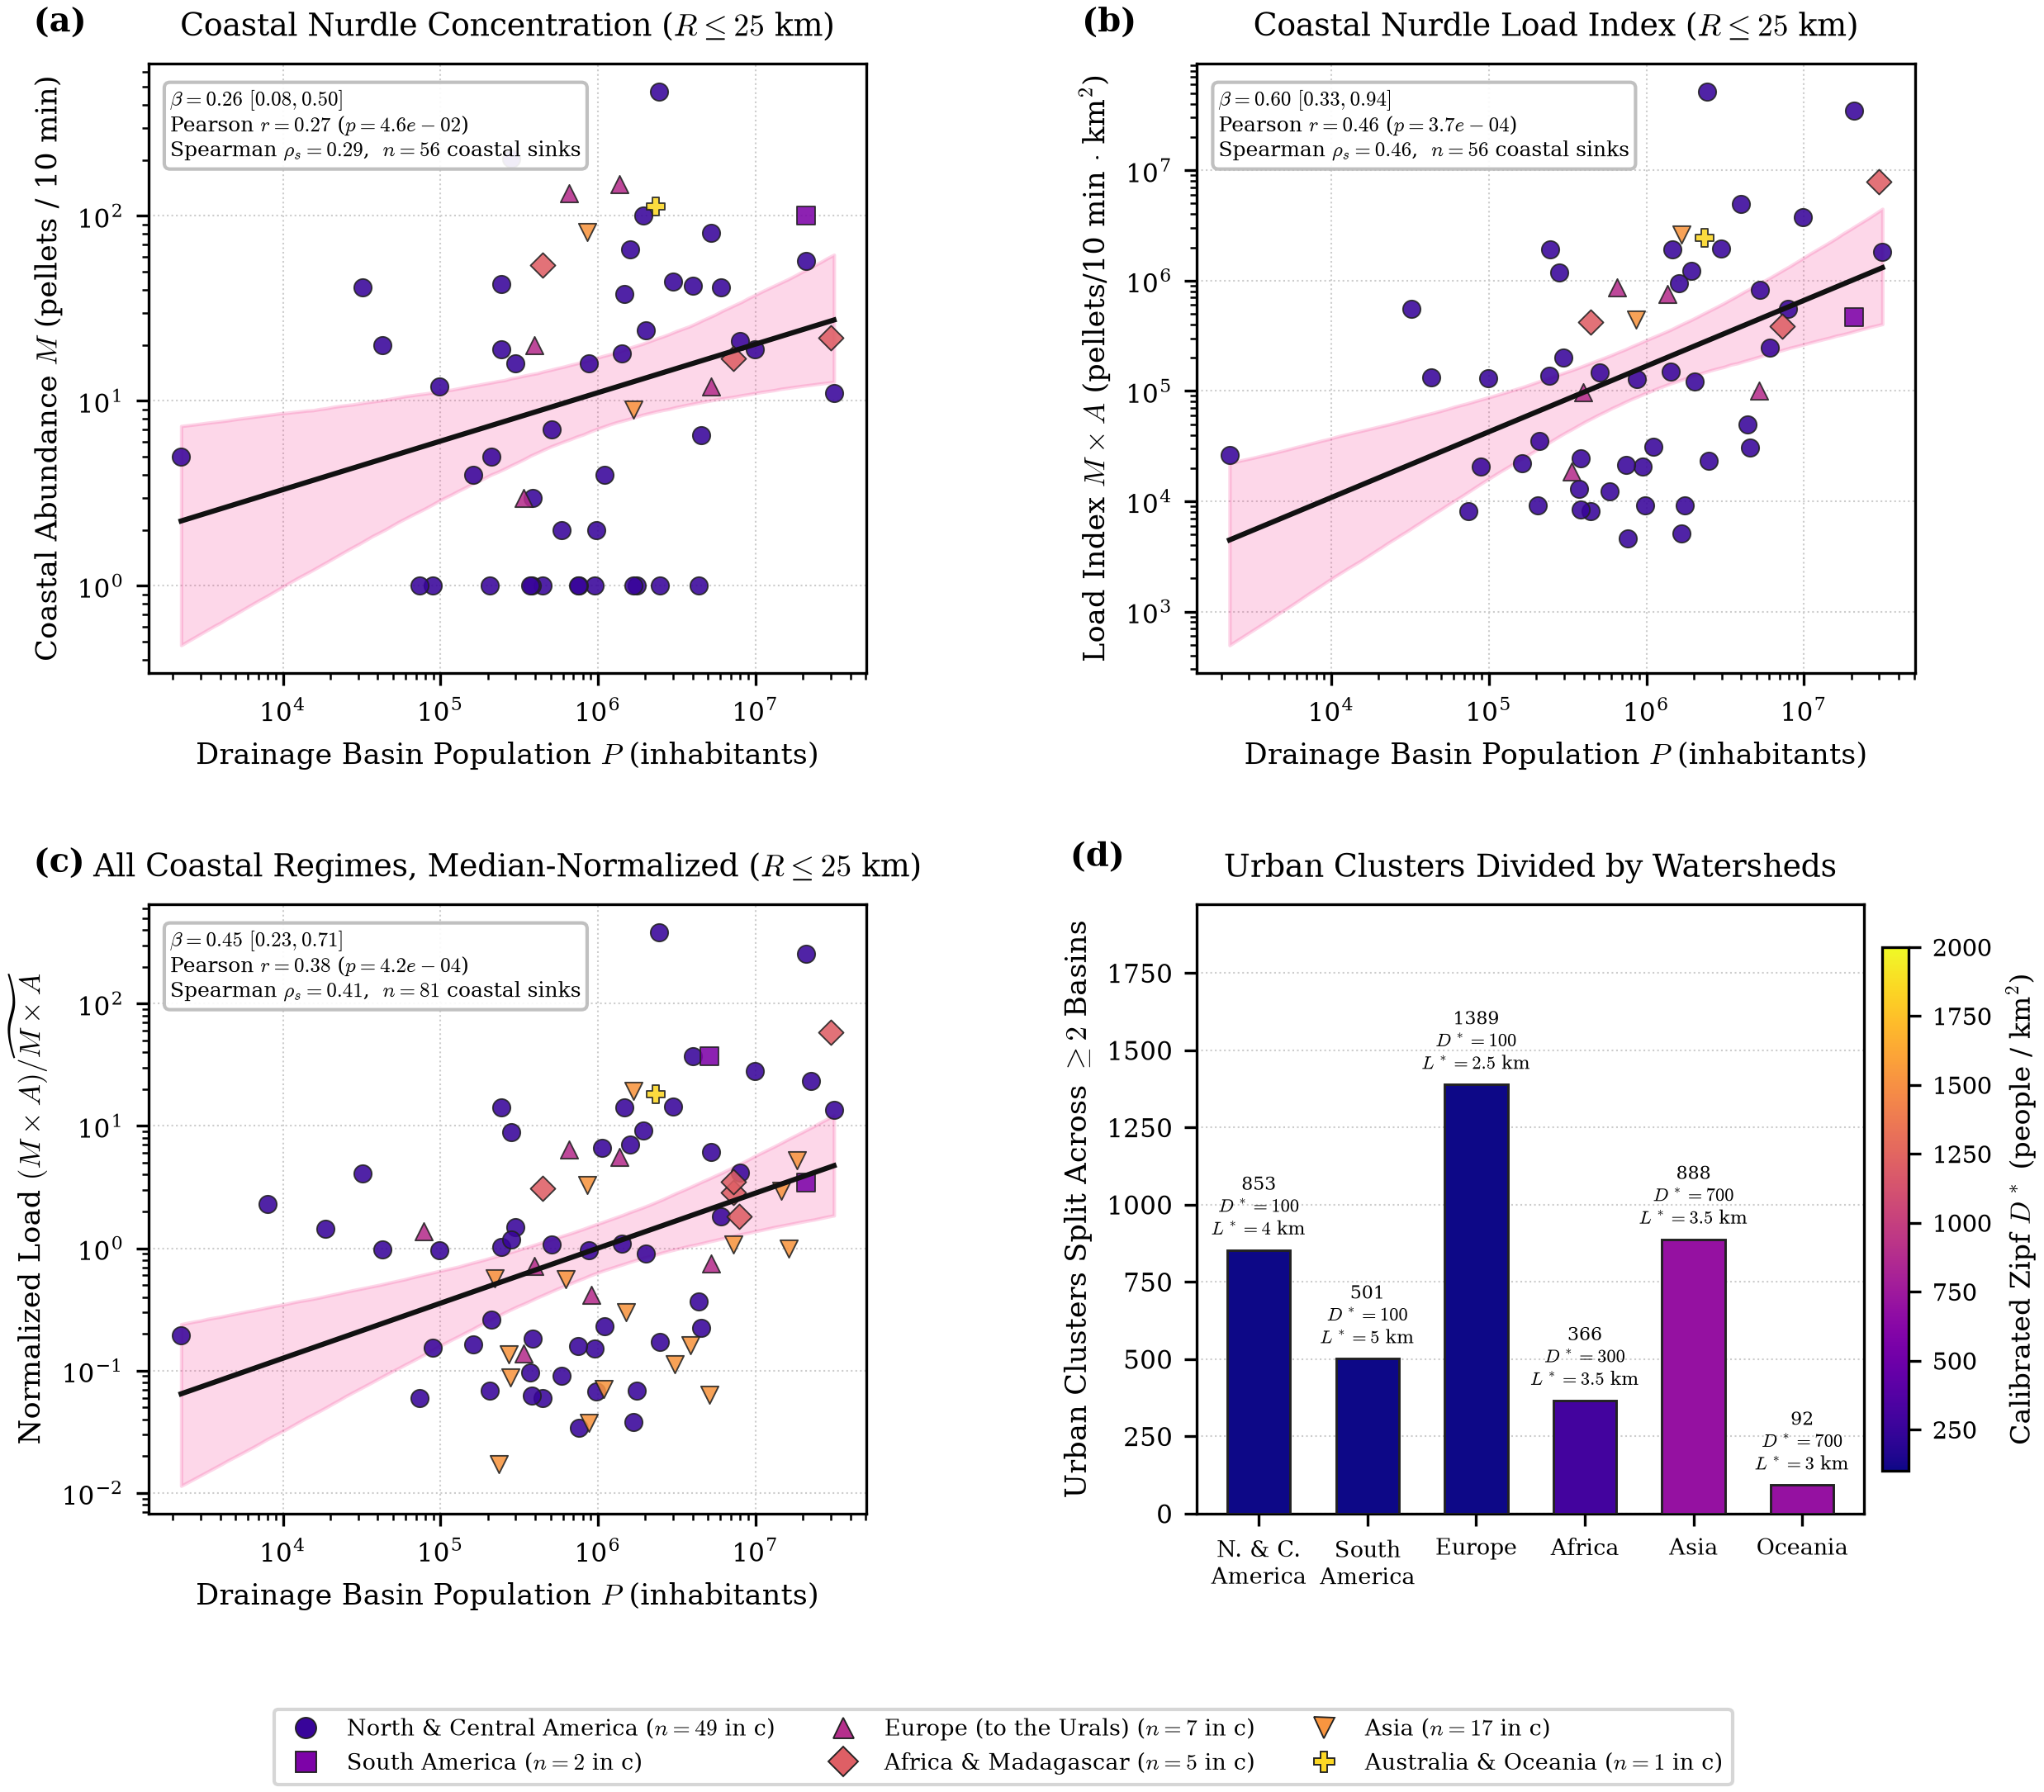

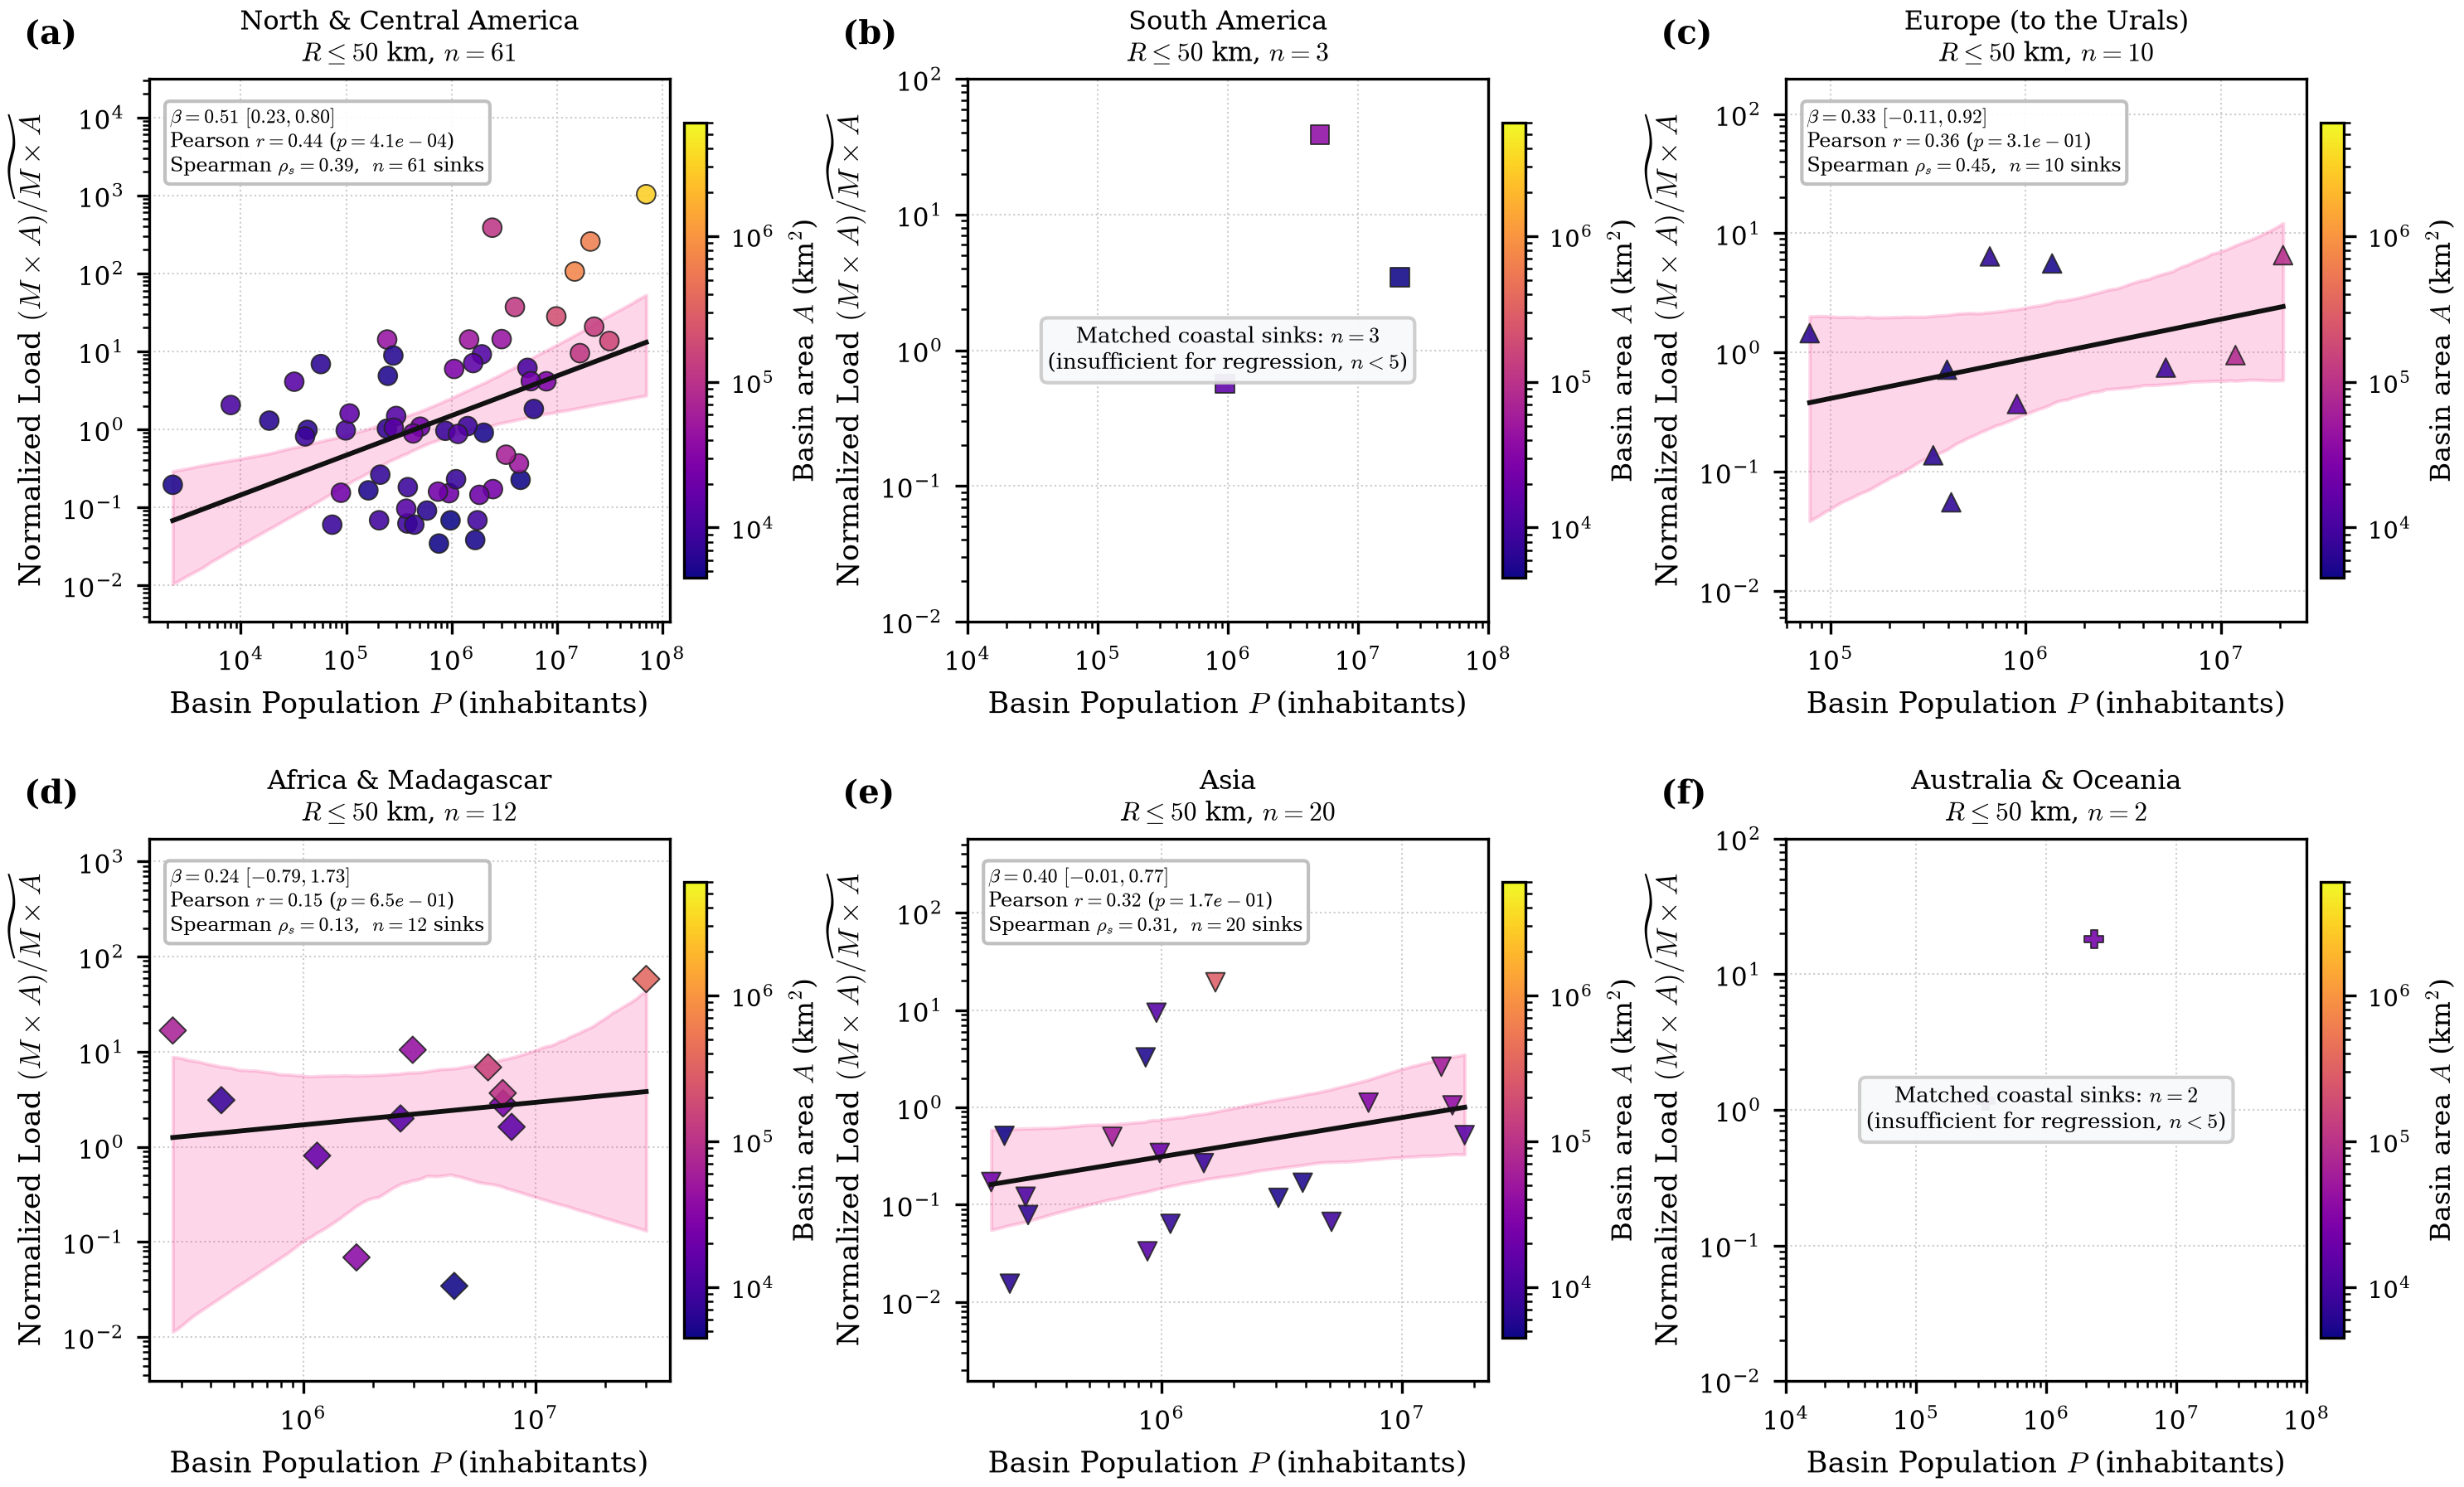

In [6]:
with open(RESULTS_DIR / "metricas_alometria_global.json", "r", encoding="utf-8") as f:
    metricas = json.load(f)

linhas = []
for un_slug, por_raio in metricas["por_unidade_e_raio"].items():
    for r_key, pares in por_raio.items():
        mc, mq = pares.get("pop_total__vs__media", {}), pares.get("pop_total__vs__qtd_x_area", {})
        if mq.get("n", 0) >= 3:
            linhas.append({"regime": un_slug, "raio": r_key, "n": mq.get("n"),
                           "beta_conc": mc.get("beta"), "r_conc": mc.get("r"),
                           "beta_MxA": mq.get("beta"), "ic95_MxA": f"[{mq.get('ic95_inf'):.2f}, {mq.get('ic95_sup'):.2f}]",
                           "r_MxA": mq.get("r"), "p_r_MxA": mq.get("p_r"), "rho_MxA": mq.get("rho"),
                           "p_perm_MxA": mq.get("p_perm")})
display(pd.DataFrame(linhas).round(4))

comp = metricas["comparativo"]
tab = []
for k in ("A_baseline_v1", "B_hidrologia_v2_noaa_legado", "C_hidrologia_v2_noaa_nova"):
    if k in comp:
        f = comp[k]["pop_total__vs__mp_x_area_norm"]
        tab.append({"cenario": k, **{c: f.get(c) for c in ("n", "beta", "ic95_inf", "ic95_sup", "r", "p_r", "rho", "p_rho", "r2", "p_perm")}})
print("Combinado global (R <= 25 km, (M x A) normalizado pela mediana vs P_total):")
display(pd.DataFrame(tab).round(4))
print("Bacias novas com coleta:", comp["bacias_novas_com_coleta"])

sub_na = df_escala[(df_escala["unidade_slug"] == "nurdle_10min") & (df_escala["territorio_id"] == "americas_norte_central_caribe")]
fit_na = ajuste_escala_log_log(sub_na["pop_total"].to_numpy(), sub_na["mp_x_area"].to_numpy(), n_boot=5000, semente=42)
loo_na = leave_one_out_alometria(sub_na["pop_total"].to_numpy(), sub_na["mp_x_area"].to_numpy(), sub_na["basin_id"].to_numpy())
print(f"\nAmérica do Norte/Central, Nurdle Patrol, R <= 25 km (n = {fit_na['n']}): beta = {fit_na['beta']:.3f} "
      f"[{fit_na['ic95_inf']:.3f}, {fit_na['ic95_sup']:.3f}] | r = {fit_na['r']:.3f} (p = {fit_na['p_r']:.1e})")
print(f"Leave-one-out: r em [{loo_na['r_sem'].min():.3f}, {loo_na['r_sem'].max():.3f}]")

display(Image(filename=str(GRAFICOS_DIR / "integrado" / "allometry_scenarios_radius_comparison.png"), width=880))
display(Image(filename=str(GRAFICOS_DIR / "integrado" / "global_allometry_population_microplastics.png"), width=880))
display(Image(filename=str(GRAFICOS_DIR / "integrado" / "allometry_correlation_6regions.png"), width=880))
